# Student Performance & At-Risk Prediction
### AI-Powered University Management System — Continuous Evaluation 1 & 2

**Course:** Artificial Intelligence & Machine Learning (24CSE0316)
**Programme:** B.E. (CSE), 5th Semester

---

## What this notebook does

The University Management System (ERP) already stores attendance, grades and
enrolments for every student. This notebook builds a **machine learning layer**
on that academic data to answer two questions **before the final exam is graded**:

| Question | Task type | Target |
|---|---|---|
| What final marks is this student heading toward? | Regression | `final_marks` |
| Is this student likely to end up academically at risk? | Classification | `at_risk` |

A third, unsupervised question is added in CE-2: **without using any labels, do
students fall into natural groups — and do those groups line up with risk?**

---
## Problem statement

Universities discover that a student is failing only *after* the final exam is
graded — at which point nothing can be done about it. The academic data that
would have signalled the problem earlier (attendance, internal marks, midterm
marks) is already sitting in the University Management System, unused for
prediction.

The existing ERP does attempt a projection, but it applies a fixed hand-written
formula that ignores attendance entirely. **The problem is to learn the
relationship from data instead of assuming it, and to flag at-risk students
while there is still time to intervene.**

## Objectives

1. **Extract and integrate** academic data from three real sources — the ERP,
   UCI Student Performance and the Open University Learning Analytics Dataset —
   into one analysis-ready dataset at one row per student-course enrolment.
2. **Pre-process the data** — clean, treat missing values, encode, engineer,
   select and scale features — so it is ready for model development.
3. **Predict a student's final marks** before the final exam (regression), using
   only information available at that point.
4. **Identify students at risk of failing** early enough to act (classification),
   prioritising *not missing* an at-risk student over avoiding false alarms.
5. **Compare six classification and three regression algorithms**, validate them
   with cross-validation, diagnose over- and under-fitting, and tune the best.
6. **Verify that machine learning genuinely improves on the ERP's existing rule**
   on the same held-out test data.
7. **Discover natural student groups without labels** (K-Means, hierarchical
   clustering, DBSCAN) and check whether they correspond to academic risk.
8. **Audit the selected model for fairness** across data sources and departments,
   and state the ethical limits of its use.

> CE-1 covered objectives 1-2 (sections 1-12). CE-2 completes the implementation
> (sections 13-26).

## Where each CE-2 presentation section is covered

| PPT section | Notebook section |
|---|---|
| Overview, problem statement, objectives | this section |
| Dataset description | 2, 3 |
| Data preprocessing | 4, 5, 7, 11, 12 |
| Exploratory data analysis | 6 |
| Feature selection / engineering | 8, 9, 10 |
| Selected algorithms and methodology | 13, 14, 19 |
| Model implementation | 12-14, 19 |
| Model evaluation and performance metrics | 15-18 |
| Results and discussion | 16, 19-22 |
| Conclusion, limitations, future scope | 25, 26 |

---
# 1. Google Colab and the essential Python libraries

Four libraries do all the work:

| Library | Role here |
|---|---|
| **NumPy** | numeric arrays; the array maths underneath Pandas and Scikit-Learn |
| **Pandas** | loading CSVs, cleaning, aggregation, the `DataFrame` |
| **Matplotlib** | every plot in this notebook |
| **Scikit-Learn** | imputers, scalers, PCA, feature selection, models, metrics |

No other libraries are used, and nothing here needs a GPU.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn

# Reproducibility: every random operation in this notebook uses this seed.
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# Every figure is also written to ai/reports/ so the PPT and the report use
# exactly the images this run produced. In Colab that folder does not exist,
# and figures are only displayed.
REPORT_DIR = "ai/reports"


def show(name):
    if os.path.isdir(REPORT_DIR):
        plt.savefig(os.path.join(REPORT_DIR, f"{name}.png"), dpi=150, bbox_inches="tight")
    plt.show()


print("NumPy       ", np.__version__)
print("Pandas      ", pd.__version__)
print("Matplotlib  ", matplotlib.__version__)
print("Scikit-Learn", sklearn.__version__)
print("\nRandom seed :", RANDOM_STATE)

NumPy        2.5.2
Pandas       3.0.5
Matplotlib   3.11.1
Scikit-Learn 1.9.0

Random seed : 42


---
# 2. Data collection

Three sources, **all real**. No synthetic data is used anywhere in this notebook.

### Source 1 — the University Management System (ERP)

The project's own PostgreSQL database. `ai/scripts/export_student_academic_data.js`
runs read-only Prisma queries and aggregates to **one row per student-course
enrolment**:

- attendance percentage - `COUNT(present=true) / COUNT(*)` per enrolment
- `internal_marks`, `midterm_marks`, `final_marks` - the three `Grade` components

### Source 2 — UCI Student Performance

> Cortez, P. (2008). *Student Performance.* UCI Machine Learning Repository.
> https://doi.org/10.24432/C5TG7T - licensed **CC BY 4.0**

Real records from two Portuguese secondary schools (1,044 student-course records).
Three sequential grades `G1 → G2 → G3` map onto internal → midterm → final.
Prepared by `ai/scripts/prepare_uci_dataset.py`.

### Source 3 — Open University Learning Analytics Dataset (OULAD) — *added in CE-2*

> Kuzilek, J., Hlosta, M. & Zdrahal, Z. (2017). Open University Learning
> Analytics dataset. *Scientific Data* 4, 170171. UCI Machine Learning
> Repository. https://doi.org/10.24432/C5KK69 - licensed **CC BY 4.0**

Real records from the UK's Open University. Only modules `CCC` and `DDD` publish a
final **exam score**, giving **4,959 student-module records** across six module
presentations (2013-2014). Prepared by `ai/scripts/prepare_oulad_dataset.py`:

| Canonical column | Built from |
|---|---|
| `final_marks` | the exam score (already 0-100) |
| `internal_marks` | weighted average of the **first half** of the module's coursework (TMA/CMA), in date order |
| `midterm_marks` | the same for the **second half** |
| `attendance_percentage` | % of course weeks with at least one interaction in the online learning environment |

Why it was added:

- **It is university data.** UCI is secondary-school data; the ERP is a university.
- **It is five times larger** than UCI, so every model has far more to learn from.
- **The OU's exam pass mark is 40** — the same as this project's at-risk threshold,
  so the label means the same thing in both systems.

### Why external sources are necessary at all — the honest reason

The ERP database currently contains **30** enrolments with a final grade and **0**
students below the at-risk threshold. A binary classifier **cannot be trained on
a single class**. So the ERP data proves the extraction pipeline and demonstrates
prediction on real students (section 23), while UCI and OULAD — which contain
genuine failures — provide the training data.

In [2]:
import io, zipfile, urllib.request

DATA_DIR  = "ai/data/raw"
UCI_CSV   = os.path.join(DATA_DIR, "uci_student_course.csv")
OULAD_CSV = os.path.join(DATA_DIR, "oulad_student_course.csv")
ERP_CSV   = os.path.join(DATA_DIR, "erp_student_course.csv")

# Canonical schema. Every source is mapped onto exactly these columns.
COLUMNS = [
    "source", "student_id", "course_code", "department", "course_type",
    "credits", "attendance_percentage", "classes_held", "internal_marks",
    "midterm_marks", "past_failures", "study_time", "final_marks", "at_risk",
]

AT_RISK_THRESHOLD = 40   # see section 2.1
GRADE_SCALE       = 5    # UCI grades are 0-20; the ERP is 0-100
NOMINAL_SESSIONS  = 60   # assumed sessions per course, to convert absences -> %


def build_uci_from_source():
    # Download UCI and map it onto the canonical schema (the Colab path).
    url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"
    with urllib.request.urlopen(url, timeout=60) as resp:
        outer = zipfile.ZipFile(io.BytesIO(resp.read()))
    inner = next((n for n in outer.namelist() if n.endswith(".zip")), None)
    src = zipfile.ZipFile(io.BytesIO(outer.read(inner))) if inner else outer

    parts = []
    for fname, ccode, dept in [("student-mat.csv", "MAT101", "MAT"),
                               ("student-por.csv", "POR101", "POR")]:
        with src.open(fname) as fh:
            raw = pd.read_csv(fh, sep=";")
        out = pd.DataFrame()
        out["source"]     = ["UCI"] * len(raw)
        out["student_id"] = [f"UCI{ccode}{i:04d}" for i in range(len(raw))]
        out["course_code"], out["department"] = ccode, dept
        out["course_type"], out["credits"]    = "MANDATORY", 3
        out["attendance_percentage"] = (
            100.0 * (1.0 - raw["absences"] / NOMINAL_SESSIONS)
        ).clip(0, 100).round(2)
        out["classes_held"]   = NOMINAL_SESSIONS
        out["internal_marks"] = raw["G1"] * GRADE_SCALE
        out["midterm_marks"]  = raw["G2"] * GRADE_SCALE
        out["final_marks"]    = raw["G3"] * GRADE_SCALE
        out["past_failures"]  = raw["failures"]
        out["study_time"]     = raw["studytime"]
        out["at_risk"] = (out["final_marks"] < AT_RISK_THRESHOLD).astype(int)
        parts.append(out[COLUMNS])
    return pd.concat(parts, ignore_index=True)


# --- UCI (local file first, download if absent) ---
if os.path.exists(UCI_CSV):
    uci = pd.read_csv(UCI_CSV)
    print(f"UCI   loaded from disk : {uci.shape[0]:5d} rows")
else:
    print("UCI CSV not found - downloading from the UCI repository...")
    uci = build_uci_from_source()
    print(f"UCI   downloaded       : {uci.shape[0]:5d} rows")

# --- OULAD (prepared by its script; needs the 45 MB archive) ---
if os.path.exists(OULAD_CSV):
    oulad = pd.read_csv(OULAD_CSV)
    print(f"OULAD loaded from disk : {oulad.shape[0]:5d} rows")
else:
    oulad = pd.DataFrame(columns=COLUMNS)
    print("OULAD CSV not found    : continuing without it")
    print("  (to generate: python ai/scripts/prepare_oulad_dataset.py)")

# --- ERP (optional) ---
if os.path.exists(ERP_CSV):
    erp = pd.read_csv(ERP_CSV)
    print(f"ERP   loaded from disk : {erp.shape[0]:5d} rows")
else:
    erp = pd.DataFrame(columns=COLUMNS)
    print("ERP CSV not found      : continuing without it")
    print("  (to generate: node ai/scripts/export_student_academic_data.js)")

UCI   loaded from disk :  1044 rows
OULAD loaded from disk :  4959 rows
ERP   loaded from disk :    30 rows


## 2.1 The prediction point, the targets, and leakage

**Prediction point:** immediately *before* the final exam is graded. The model may
only see what exists at that moment - attendance, internal marks, midterm marks.

**Regression target:** `final_marks` (0-100).

**Classification target:**

```
at_risk = 1  when final_marks < 40
at_risk = 0  otherwise
```

### Why the threshold is 40, not 35

The ERP's grading scale makes `F` the only failing grade, at `< 35`, and `P`
(35-39) a bare pass. So why 40?

Because the ERP's **own** definition of academic risk is already broader. In
`server/lib/timetableInsights.js`:

```js
const gradeRisk = ['F', 'P'].includes(prediction.projectedGrade)
```

The application already treats a bare pass as a student needing attention. `P`
ends at 39, so `final_marks < 40` reproduces that existing domain rule exactly.
The threshold comes from the codebase, not from convenience.

It also matches the outside world: the **Open University's exam pass mark is 40**,
so for OULAD students `at_risk = 1` means exactly "failed the exam".

### Leakage — what is deliberately excluded

Data leakage means letting the model see the answer. All of these are barred from
the feature set:

| Excluded | Why |
|---|---|
| `final_marks` as a feature | it *is* the regression target |
| `at_risk` as a feature | derived directly from the target |
| `letterGrade` | computed from `final_marks` |
| GPA | computed from the FINAL component only |
| Output of `predictFinalGrade` | that ERP function reads FINAL when it is present |

Rows with **no** final grade are **dropped, not imputed**. A missing final is a
missing *outcome*, not a missing feature - imputing it would mean inventing the
label. The ERP export already drops these (15 of its 45 enrolments).

---
# 3. Data integration

Three sources with different original schemas, combined into one frame.

Most of the integration work happens in the three preparation scripts, and that is
the point: all three emit **identical columns**, so integration here is a
*verified* concatenation rather than a hopeful one.

| Canonical column | ERP | UCI | OULAD |
|---|---|---|---|
| `attendance_percentage` | `COUNT(present)/COUNT(*)` | `100 x (1 - absences/60)` | % of weeks active online |
| `internal_marks` | `Grade` INTERNAL | `G1 x 5` | 1st half of coursework |
| `midterm_marks` | `Grade` MID_TERM | `G2 x 5` | 2nd half of coursework |
| `final_marks` | `Grade` FINAL | `G3 x 5` | exam score |
| `past_failures` | *not available* | `failures` | `num_of_prev_attempts` |
| `study_time` | *not available* | `studytime` | *not available* |
| `course_type` | `Course.type` | `MANDATORY` | *not recorded* |

Alignments that were required:

- **Grade scale.** UCI uses the Portuguese 0-20 scale and is multiplied by 5. The ERP and OULAD are already 0-100.
- **Attendance.** Three different measurements become one column: a class register (ERP), an absence count converted with an assumed 60 sessions (UCI), and weekly online engagement (OULAD — a distance university has no classroom register). This is the largest modelling assumption in the project and is revisited in section 25.

A `source` column is kept so every row can be traced back to where it came from.

In [3]:
frames = [f for f in (uci, oulad, erp) if len(f)]
df = pd.concat(frames, ignore_index=True)

print("Integrated dataset:", df.shape)
print("\nRows by source:")
print(df["source"].value_counts().to_string())
print("\nSchemas identical across sources:", all(list(f.columns) == COLUMNS for f in frames))

df.groupby("source").head(2)

Integrated dataset: (6033, 14)

Rows by source:
source
OULAD    4959
UCI      1044
ERP        30

Schemas identical across sources: True


,source,student_id,course_code,department,course_type,credits,attendance_percentage,classes_held,internal_marks,midterm_marks,past_failures,study_time,final_marks,at_risk
0,UCI,UCIMAT1010000,MAT101,MAT,MANDATORY,3.0,90.00,60,25.00,30.00,0.0,2.0,30.0,1
1,UCI,UCIMAT1010001,MAT101,MAT,MANDATORY,3.0,93.33,60,25.00,25.00,0.0,2.0,30.0,1
1044,OULAD,OU2672686,DDD-2013B,DDD,NaN,NaN,100.00,35,92.06,94.93,0.0,NaN,78.0,0
1045,OULAD,OU2689536,DDD-2013B,DDD,NaN,NaN,65.71,35,84.07,22.24,0.0,NaN,58.0,0
6003,ERP,user_6,CSE210,CSE,MANDATORY,4.0,94.12,17,75.00,78.00,NaN,NaN,82.0,0
6004,ERP,user_6,CSE320,CSE,MANDATORY,3.0,87.50,16,68.00,72.00,NaN,NaN,75.0,0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6033 entries, 0 to 6032
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   source                 6033 non-null   str    
 1   student_id             6033 non-null   str    
 2   course_code            6033 non-null   str    
 3   department             6033 non-null   str    
 4   course_type            1074 non-null   object 
 5   credits                1074 non-null   float64
 6   attendance_percentage  6033 non-null   float64
 7   classes_held           6033 non-null   int64  
 8   internal_marks         6033 non-null   float64
 9   midterm_marks          6033 non-null   float64
 10  past_failures          6003 non-null   float64
 11  study_time             1044 non-null   float64
 12  final_marks            6033 non-null   float64
 13  at_risk                6033 non-null   int64  
dtypes: float64(7), int64(2), object(1), str(4)
memory usage: 660.0+ KB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
credits,1074.0,3.012104,0.109403,3.0,3.00,3.00,3.00,4.0
attendance_percentage,6033.0,82.460554,16.046162,0.0,73.68,86.84,94.74,100.0
classes_held,6033.0,40.945964,9.009706,7.0,35.00,38.00,39.00,60.0
internal_marks,6033.0,70.585107,21.431076,0.0,60.00,76.06,87.00,100.0
midterm_marks,6033.0,60.767834,23.016429,0.0,45.00,62.67,80.00,100.0
past_failures,6003.0,0.144095,0.454962,0.0,0.00,0.00,0.00,5.0
study_time,1044.0,1.970307,0.834353,1.0,1.00,2.00,2.00,4.0
final_marks,6033.0,64.113376,20.639006,0.0,50.00,64.00,80.00,100.0
at_risk,6033.0,0.110559,0.313611,0.0,0.00,0.00,0.00,1.0


---
# 4. Data cleaning

Four checks, in order. Each one prints what it removed so nothing disappears
silently.

1. **Exact duplicate rows** - the same student-course record ingested twice.
2. **Duplicate identity keys** - the same `(source, student_id, course_code)` appearing more than once, which would break the one-row-per-enrolment grain.
3. **Impossible marks** - any of the three mark columns outside 0-100.
4. **Impossible attendance** - a percentage outside 0-100.

A guiding rule: **do not silently drop large portions of the data.** If a check
removed a big share of rows that would be a signal that the check is wrong, not
that the data is bad, so the row count is reported at every step.

In [6]:
clean = df.copy()
report = []


def log(step, before, after):
    report.append({"step": step, "rows_before": before,
                   "rows_after": after, "removed": before - after})


# 1. exact duplicate rows
n = len(clean); clean = clean.drop_duplicates(); log("exact duplicates", n, len(clean))

# 2. duplicate identity keys (breaks the one-row-per-enrolment grain)
n = len(clean)
clean = clean.drop_duplicates(subset=["source", "student_id", "course_code"], keep="first")
log("duplicate identity keys", n, len(clean))

# 3. impossible marks
MARK_COLS = ["internal_marks", "midterm_marks", "final_marks"]
n = len(clean)
valid_marks = pd.Series(True, index=clean.index)
for c in MARK_COLS:
    col = pd.to_numeric(clean[c], errors="coerce")
    valid_marks &= col.isna() | col.between(0, 100)
clean = clean[valid_marks]
log("marks outside 0-100", n, len(clean))

# 4. impossible attendance
n = len(clean)
att = pd.to_numeric(clean["attendance_percentage"], errors="coerce")
clean = clean[att.isna() | att.between(0, 100)]
log("attendance outside 0-100", n, len(clean))

print(pd.DataFrame(report).to_string(index=False))
print(f"\nRetained {len(clean)} of {len(df)} rows "
      f"({100 * len(clean) / len(df):.1f}%)")

                    step  rows_before  rows_after  removed
        exact duplicates         6033        6033        0
 duplicate identity keys         6033        6033        0
     marks outside 0-100         6033        6033        0
attendance outside 0-100         6033        6033        0

Retained 6033 of 6033 rows (100.0%)


### Dropping rows with no outcome

The final cleaning step is the one that matters most for correctness: a row with
no `final_marks` has **no label**. It cannot be used for supervised training, and
imputing the label would mean inventing the answer the model is supposed to learn.

These rows are dropped, not filled.

In [7]:
n = len(clean)
clean = clean[clean["final_marks"].notna()].copy()
print(f"Dropped {n - len(clean)} rows with no final_marks (no label)")
print(f"Remaining: {len(clean)} rows")

# Recompute the target from the cleaned marks so it can never drift out of sync
# with final_marks after cleaning.
clean["at_risk"] = (clean["final_marks"] < AT_RISK_THRESHOLD).astype(int)

print("\nTarget balance:")
counts = clean["at_risk"].value_counts().sort_index()
for k, v in counts.items():
    label = "at risk" if k == 1 else "not at risk"
    print(f"  {k} ({label:11}): {v:5d}  ({100 * v / len(clean):5.1f}%)")

Dropped 0 rows with no final_marks (no label)
Remaining: 6033 rows

Target balance:
  0 (not at risk):  5366  ( 88.9%)
  1 (at risk    ):   667  ( 11.1%)


---
# 5. Handling missing values

There are two *different kinds* of missingness here, and they need different
treatment. Conflating them is a common and costly mistake.

### Kind 1 — structurally missing (a whole column absent for one source)

Some columns simply do not exist in some sources: the ERP records no
`past_failures` or `study_time`; the Open University records no `study_time`,
`credits` or `course_type`. These are missing for **every** row of that source, by
construction. This is a schema difference, not random noise.

### Kind 2 — genuinely missing values (a gap within a column that exists)

For example a student whose internal mark was never entered. These are scattered
and can reasonably be imputed.

**Kind 2 imputation is deliberately *not* done here.** It is defined inside the
scikit-learn `Pipeline` in section 12, so the median is computed from the
**training fold only**. Computing it now, over the whole dataset, would leak
test-set information into training.

In [8]:
miss = pd.DataFrame({
    "missing": clean.isna().sum(),
    "percent": (100 * clean.isna().mean()).round(1),
})
miss = miss[miss["missing"] > 0].sort_values("missing", ascending=False)

if len(miss):
    print("Columns containing missing values:\n")
    print(miss.to_string())
else:
    print("No missing values.")

# Structural missingness is source-specific - show it explicitly.
print("\nMissing rate by source (1.0 = the source does not record it at all):")
print(clean.groupby("source")[["course_type", "credits", "past_failures", "study_time"]]
      .apply(lambda g: g.isna().mean().round(3)).to_string())

Columns containing missing values:

               missing  percent
study_time        4989     82.7
course_type       4959     82.2
credits           4959     82.2
past_failures       30      0.5

Missing rate by source (1.0 = the source does not record it at all):
        course_type  credits  past_failures  study_time
source                                                 
ERP             0.0      0.0            1.0         1.0
OULAD           1.0      1.0            0.0         1.0
UCI             0.0      0.0            0.0         0.0


**Decisions.** Each structurally-missing column is treated on its merits:

| Column | Missing for | Decision | Why |
|---|---|---|---|
| `past_failures` | ERP (100%) | **dropped** from the features | the ERP cannot supply it, so a model that needs it could not score a single real ERP student |
| `study_time` | ERP and OULAD (100%) | **dropped** | the same reason, for two of three sources |
| `credits` | OULAD (100%) | **dropped** | also near-constant elsewhere (measured in section 9) |
| `course_type` | OULAD (100%) | **kept**, with an explicit `NOT_RECORDED` category | for a categorical column, "not recorded" is honest information; filling it with the most common value would invent a fact about 4,959 students |

Their predictive value is measured in section 9 before the decisions are final,
rather than assumed.

In [9]:
# Kind 1 treatment for the one structurally-missing categorical column we keep.
n_missing = int(clean["course_type"].isna().sum())
clean["course_type"] = clean["course_type"].fillna("NOT_RECORDED")
print(f"course_type: {n_missing} missing values -> explicit 'NOT_RECORDED' category\n")
print(pd.crosstab(clean["source"], clean["course_type"]).to_string())

course_type: 4959 missing values -> explicit 'NOT_RECORDED' category

course_type  ELECTIVE  MANDATORY  NOT_RECORDED
source                                        
ERP                10         20             0
OULAD               0          0          4959
UCI                 0       1044             0


---
# 6. Exploratory data analysis

Each plot answers a specific question. The aim is to understand the data before
modelling it, not to produce a gallery. With three sources, one extra question
matters: **do the sources behave alike?**

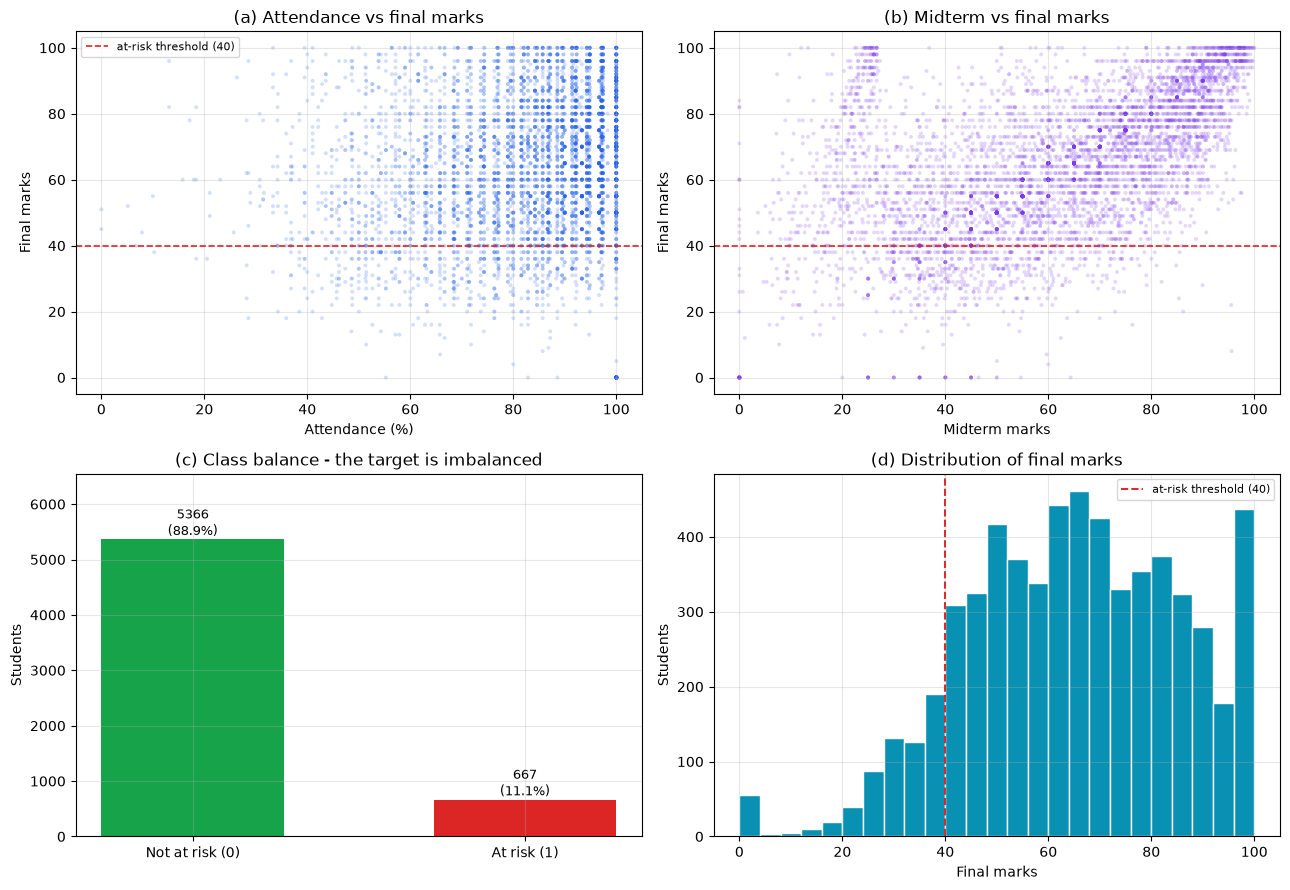

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# (a) attendance vs final marks
ax = axes[0, 0]
ax.scatter(clean["attendance_percentage"], clean["final_marks"],
           alpha=0.2, s=8, color="#2563eb", edgecolors="none")
ax.axhline(AT_RISK_THRESHOLD, color="#dc2626", ls="--", lw=1.2,
           label=f"at-risk threshold ({AT_RISK_THRESHOLD})")
ax.set_xlabel("Attendance (%)"); ax.set_ylabel("Final marks")
ax.set_title("(a) Attendance vs final marks"); ax.legend(fontsize=8)

# (b) midterm vs final marks
ax = axes[0, 1]
ax.scatter(clean["midterm_marks"], clean["final_marks"],
           alpha=0.2, s=8, color="#7c3aed", edgecolors="none")
ax.axhline(AT_RISK_THRESHOLD, color="#dc2626", ls="--", lw=1.2)
ax.set_xlabel("Midterm marks"); ax.set_ylabel("Final marks")
ax.set_title("(b) Midterm vs final marks")

# (c) target distribution
ax = axes[1, 0]
vc = clean["at_risk"].value_counts().sort_index()
bars = ax.bar(["Not at risk (0)", "At risk (1)"], vc.values,
              color=["#16a34a", "#dc2626"], width=0.55)
for bar, v in zip(bars, vc.values):
    ax.text(bar.get_x() + bar.get_width() / 2, v, f"{v}\n({100*v/len(clean):.1f}%)",
            ha="center", va="bottom", fontsize=9)
ax.set_ylabel("Students"); ax.set_title("(c) Class balance - the target is imbalanced")
ax.set_ylim(0, vc.max() * 1.22)

# (d) final marks distribution
ax = axes[1, 1]
ax.hist(clean["final_marks"], bins=25, color="#0891b2", edgecolor="white")
ax.axvline(AT_RISK_THRESHOLD, color="#dc2626", ls="--", lw=1.4,
           label=f"at-risk threshold ({AT_RISK_THRESHOLD})")
ax.set_xlabel("Final marks"); ax.set_ylabel("Students")
ax.set_title("(d) Distribution of final marks"); ax.legend(fontsize=8)

plt.tight_layout(); show("01_eda_overview")

**What these show.**

- **(a)** Attendance is positively but *loosely* associated with final marks. High attendance does not guarantee a high mark, which is why a single cutoff on attendance is a weak predictor on its own.
- **(b)** The midterm is the strongest single predictor of the final, but with three sources the cloud is far wider than in CE-1 — many students with a good midterm still score low in the final exam.
- **(c)** The classes are **imbalanced** — 667 of 6,033 students (11.1%) are at risk. This drives two later decisions: stratified splitting (section 12) and judging models on recall/F2 rather than accuracy (section 13).
- **(d)** The spike at zero is real. In UCI a final mark of 0 records a student who stopped attending, and in OULAD it is a student who sat the exam and scored nothing. These are genuine at-risk cases, not data errors.

        rows  at_risk_%  mean_final  mean_attendance  corr(midterm,final)  corr(attendance,final)
source                                                                                           
UCI     1044      9.579      56.710           92.633                0.911                   0.045
OULAD   4959     11.434      65.573           80.263                0.476                   0.232
ERP       30      0.000      80.500           91.808                0.998                   0.788


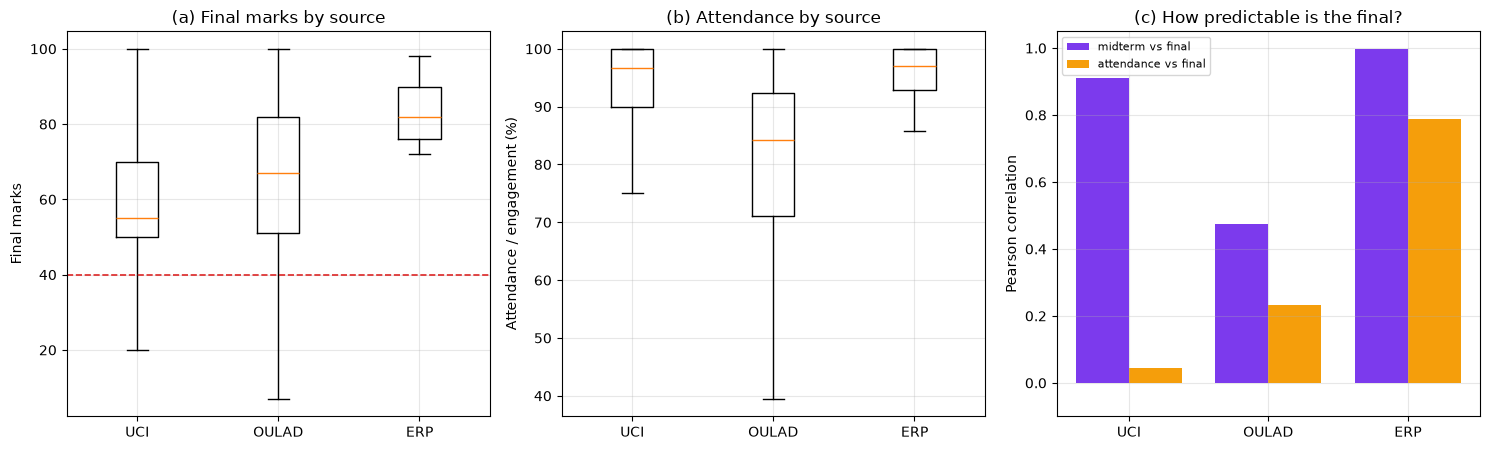

In [11]:
# Do the three sources behave alike? Distribution and predictability per source.
src_order  = [s for s in ["UCI", "OULAD", "ERP"] if s in set(clean["source"])]
src_colors = {"UCI": "#2563eb", "OULAD": "#7c3aed", "ERP": "#16a34a"}


def corr_in(source, col):
    part = clean[clean["source"] == source]
    return part[[col, "final_marks"]].corr().iloc[0, 1]


source_summary = pd.DataFrame({
    "rows":               clean.groupby("source").size(),
    "at_risk_%":          100 * clean.groupby("source")["at_risk"].mean(),
    "mean_final":         clean.groupby("source")["final_marks"].mean(),
    "mean_attendance":    clean.groupby("source")["attendance_percentage"].mean(),
    "corr(midterm,final)":    [corr_in(s, "midterm_marks") for s in clean.groupby("source").size().index],
    "corr(attendance,final)": [corr_in(s, "attendance_percentage") for s in clean.groupby("source").size().index],
}).loc[src_order]
print(source_summary.round(3).to_string())

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
ax = axes[0]
ax.boxplot([clean.loc[clean["source"] == s, "final_marks"] for s in src_order],
           tick_labels=src_order, showfliers=False)
ax.axhline(AT_RISK_THRESHOLD, color="#dc2626", ls="--", lw=1.2)
ax.set_ylabel("Final marks"); ax.set_title("(a) Final marks by source")

ax = axes[1]
ax.boxplot([clean.loc[clean["source"] == s, "attendance_percentage"] for s in src_order],
           tick_labels=src_order, showfliers=False)
ax.set_ylabel("Attendance / engagement (%)"); ax.set_title("(b) Attendance by source")

ax = axes[2]
xs = np.arange(len(src_order)); w = 0.38
ax.bar(xs - w/2, source_summary["corr(midterm,final)"], w, label="midterm vs final", color="#7c3aed")
ax.bar(xs + w/2, source_summary["corr(attendance,final)"], w, label="attendance vs final", color="#f59e0b")
ax.set_xticks(xs); ax.set_xticklabels(src_order); ax.set_ylim(-0.1, 1.05)
ax.set_ylabel("Pearson correlation"); ax.set_title("(c) How predictable is the final?")
ax.legend(fontsize=8)
plt.tight_layout(); show("02_source_comparison")

**The three sources do *not* behave alike — and this is the most important finding of the EDA.**

| | UCI | OULAD | ERP |
|---|---|---|---|
| correlation of midterm with final | **0.91** | **0.48** | 1.00 |
| correlation of attendance with final | 0.05 | **0.23** | 0.79 |

- In **UCI**, the three grades `G1, G2, G3` are near-copies of each other — so the final is almost fully predictable from the midterm. This is why CE-1 reported R² = 0.88: the UCI task was easy.
- In **OULAD**, the final is a separate written exam, and coursework predicts it far less well. That is a more realistic picture of a university, where a student can do the assignments and still fail the exam.
- In **OULAD**, attendance (online engagement) carries real signal (0.23); in UCI it carries almost none (0.05). Adding OULAD is what gives the attendance feature something to learn from.
- The **ERP** rows are 30 near-perfect students — useful for the deployment demo, too few and too uniform to say anything statistical.

**Consequence for everything that follows:** metrics in CE-2 are lower than in CE-1, because the task is now harder and more honest — not because the models are worse.

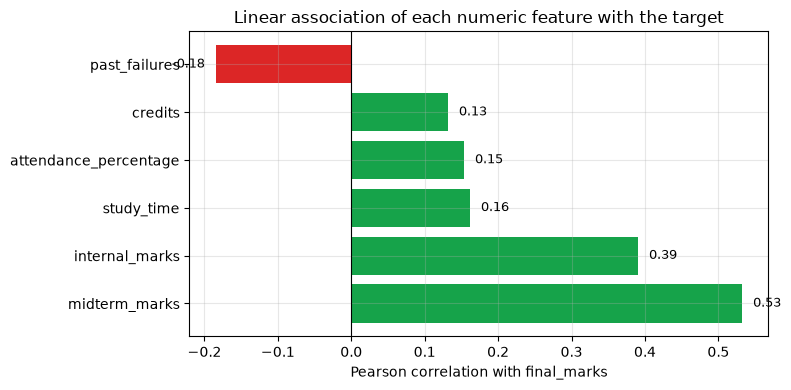

midterm_marks            0.532
internal_marks           0.391
study_time               0.162
attendance_percentage    0.153
credits                  0.132
past_failures           -0.185


In [12]:
# Correlation of the numeric columns with the regression target.
num_cols = ["attendance_percentage", "internal_marks", "midterm_marks",
            "past_failures", "study_time", "credits", "final_marks"]
corr = clean[num_cols].corr(numeric_only=True)["final_marks"].drop("final_marks")
corr = corr.sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 4))
colors = ["#16a34a" if v > 0 else "#dc2626" for v in corr.values]
ax.barh(corr.index, corr.values, color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Pearson correlation with final_marks")
ax.set_title("Linear association of each numeric feature with the target")
for i, v in enumerate(corr.values):
    ax.text(v + (0.015 if v > 0 else -0.015), i, f"{v:.2f}",
            va="center", ha="left" if v > 0 else "right", fontsize=9)
plt.tight_layout(); show("03_correlation_with_target")

print(corr.round(3).to_string())

---
# 7. Data transformation

Two transformations are needed before any model can consume this data.

**Categorical encoding.** `department` and `course_type` are text. Models need
numbers. These are *nominal* categories with no natural ordering, so one-hot
encoding is correct — label-encoding them would invent a false ordering
(`CSE < ECE < MAT`), which a linear model would then take seriously.

**Numeric passthrough.** The mark and attendance columns are already on a common
0-100 scale after the integration step in section 3, so they need no transform
here. Scaling is handled separately in section 11.

As with imputation, the encoder is **fitted inside the pipeline** so its learned
categories come from the training fold only.

In [13]:
from sklearn.preprocessing import OneHotEncoder

# Demonstrate the encoding here so its effect is visible; the version that is
# actually fitted lives inside the pipeline in section 12.
CATEGORICAL = ["department", "course_type"]

demo_enc = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
encoded = demo_enc.fit_transform(clean[CATEGORICAL])
encoded_names = demo_enc.get_feature_names_out(CATEGORICAL)

print(f"{len(CATEGORICAL)} categorical columns -> {encoded.shape[1]} binary columns\n")
print("Generated columns:", list(encoded_names))
print("\nFirst 5 encoded rows:")
print(pd.DataFrame(encoded[:5], columns=encoded_names).to_string(index=False))

2 categorical columns -> 9 binary columns

Generated columns: ['department_CCC', 'department_CSE', 'department_DDD', 'department_ECE', 'department_MAT', 'department_POR', 'course_type_ELECTIVE', 'course_type_MANDATORY', 'course_type_NOT_RECORDED']

First 5 encoded rows:
 department_CCC  department_CSE  department_DDD  department_ECE  department_MAT  department_POR  course_type_ELECTIVE  course_type_MANDATORY  course_type_NOT_RECORDED
            0.0             0.0             0.0             0.0             1.0             0.0                   0.0                    1.0                       0.0
            0.0             0.0             0.0             0.0             1.0             0.0                   0.0                    1.0                       0.0
            0.0             0.0             0.0             0.0             1.0             0.0                   0.0                    1.0                       0.0
            0.0             0.0             0.0             0

---
# 8. Feature engineering

Three new features, each with a stated reason. Features are not added to inflate
the count — every one has to answer "what does this tell the model that the raw
columns do not?"

| Feature | Definition | Why |
|---|---|---|
| `internal_midterm_average` | mean of internal and midterm | A single summary of standing so far. Smooths a one-off bad paper that either column alone would over-weight. |
| `performance_trend` | `midterm - internal` | **Direction of travel.** Two students on 60 are not equivalent if one rose 40→60 and the other fell 80→60. No raw column carries this. |
| `attendance_band` | `SAFE` / `WARNING` / `CRITICAL` | Applies the ERP's own 75% / 65% thresholds from `timetableInsights.js`, letting the model use the institution's rule as a signal. |

**Leakage check.** All three derive only from internal marks, midterm marks and
attendance — all known *before* the final exam. None touches `final_marks`.

In [14]:
def engineer(frame):
    # All inputs are known before the final exam - see the leakage check above.
    out = frame.copy()

    out["internal_midterm_average"] = out[["internal_marks", "midterm_marks"]].mean(axis=1)
    out["performance_trend"] = out["midterm_marks"] - out["internal_marks"]

    # The ERP's own attendance bands (server/lib/timetableInsights.js):
    #   >= 75 SAFE | 65-74 WARNING | < 65 CRITICAL
    out["attendance_band"] = pd.cut(
        out["attendance_percentage"],
        bins=[-np.inf, 65, 75, np.inf],
        labels=["CRITICAL", "WARNING", "SAFE"],
    ).astype(object)

    return out


featured = engineer(clean)

print("New features:\n")
print(featured[["internal_marks", "midterm_marks", "internal_midterm_average",
                "performance_trend", "attendance_percentage",
                "attendance_band"]].head(8).to_string(index=False))

print("\nAttendance band distribution:")
print(featured["attendance_band"].value_counts().to_string())

New features:

 internal_marks  midterm_marks  internal_midterm_average  performance_trend  attendance_percentage attendance_band
           25.0           30.0                      27.5                5.0                  90.00            SAFE
           25.0           25.0                      25.0                0.0                  93.33            SAFE
           35.0           40.0                      37.5                5.0                  83.33            SAFE
           75.0           70.0                      72.5               -5.0                  96.67            SAFE
           30.0           50.0                      40.0               20.0                  93.33            SAFE
           75.0           75.0                      75.0                0.0                  83.33            SAFE
           60.0           60.0                      60.0                0.0                 100.00            SAFE
           30.0           25.0                      27.5         

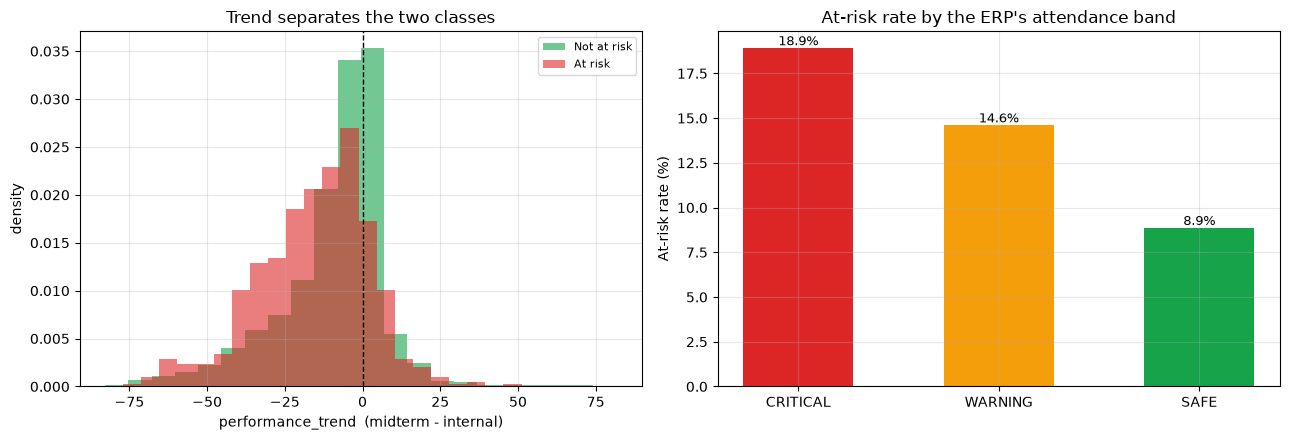

In [15]:
# Does performance_trend actually separate the classes? If it does not, it does
# not belong in the feature set.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
for label, colour, name in [(0, "#16a34a", "Not at risk"), (1, "#dc2626", "At risk")]:
    subset = featured.loc[featured["at_risk"] == label, "performance_trend"]
    ax.hist(subset, bins=22, alpha=0.6, color=colour, label=name, density=True)
ax.axvline(0, color="black", lw=1, ls="--")
ax.set_xlabel("performance_trend  (midterm - internal)")
ax.set_ylabel("density"); ax.set_title("Trend separates the two classes")
ax.legend(fontsize=8)

ax = axes[1]
band_order = ["CRITICAL", "WARNING", "SAFE"]
rates = [100 * featured.loc[featured["attendance_band"] == bnd, "at_risk"].mean()
         for bnd in band_order]
bars = ax.bar(band_order, rates, color=["#dc2626", "#f59e0b", "#16a34a"], width=0.55)
for bar, v in zip(bars, rates):
    ax.text(bar.get_x() + bar.get_width() / 2, v, f"{v:.1f}%",
            ha="center", va="bottom", fontsize=9)
ax.set_ylabel("At-risk rate (%)")
ax.set_title("At-risk rate by the ERP's attendance band")

plt.tight_layout(); show("04_feature_engineering_check")

---
# 9. Feature selection

Two complementary methods, because each sees something the other misses:

- **Pearson correlation** measures *linear* association with `final_marks`. Simple and readable, but blind to non-linear relationships.
- **Mutual information** measures *any* statistical dependence, linear or not. It catches relationships correlation scores as zero.

`SelectKBest` then formalises the ranking. This is also where the earlier claim
about `past_failures` and `study_time` gets tested rather than assumed.

In [16]:
from sklearn.feature_selection import (
    SelectKBest, mutual_info_classif, mutual_info_regression, f_regression,
)

CANDIDATES = [
    "attendance_percentage", "internal_marks", "midterm_marks",
    "internal_midterm_average", "performance_trend", "credits",
    "past_failures", "study_time",
]

# Median-fill ONLY for this ranking step, so the scores are comparable across
# columns. The model itself imputes inside the pipeline (section 12).
X_rank = featured[CANDIDATES].apply(pd.to_numeric, errors="coerce")
X_rank = X_rank.fillna(X_rank.median())

mi_clf = mutual_info_classif(X_rank, featured["at_risk"], random_state=RANDOM_STATE)
mi_reg = mutual_info_regression(X_rank, featured["final_marks"], random_state=RANDOM_STATE)
pearson = X_rank.corrwith(featured["final_marks"]).abs()

ranking = pd.DataFrame({
    "abs_correlation": pearson.values,
    "mutual_info_regression": mi_reg,
    "mutual_info_classification": mi_clf,
}, index=CANDIDATES).sort_values("mutual_info_regression", ascending=False)

print(ranking.round(3).to_string())

                          abs_correlation  mutual_info_regression  mutual_info_classification
internal_midterm_average            0.504                   0.663                       0.086
midterm_marks                       0.532                   0.655                       0.072
internal_marks                      0.391                   0.599                       0.077
attendance_percentage               0.153                   0.323                       0.008
performance_trend                   0.223                   0.319                       0.013
study_time                          0.068                   0.142                       0.000
past_failures                       0.185                   0.032                       0.007
credits                             0.037                   0.000                       0.002


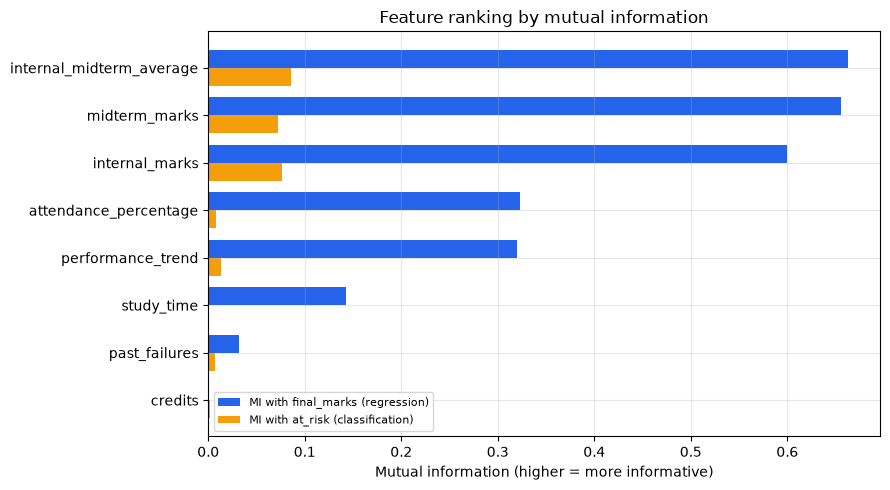

In [17]:
fig, ax = plt.subplots(figsize=(9, 5))
order = ranking.sort_values("mutual_info_regression")
y = np.arange(len(order)); h = 0.38

ax.barh(y + h/2, order["mutual_info_regression"], height=h,
        color="#2563eb", label="MI with final_marks (regression)")
ax.barh(y - h/2, order["mutual_info_classification"], height=h,
        color="#f59e0b", label="MI with at_risk (classification)")
ax.set_yticks(y); ax.set_yticklabels(order.index)
ax.set_xlabel("Mutual information (higher = more informative)")
ax.set_title("Feature ranking by mutual information")
ax.legend(fontsize=8)
plt.tight_layout(); show("05_feature_selection_mutual_info")

**Result.** The mark-based features dominate on every measure; `internal_midterm_average` now
ranks first, ahead of either mark alone. `attendance_percentage` and `performance_trend` rank
clearly above the remaining candidates on mutual information (0.32 each) — much higher than in
CE-1, because OULAD's engagement data carries real signal. `credits` carries almost nothing.

`past_failures` and `study_time` do carry some signal, but they are missing for 100% of ERP rows
(section 5). They are excluded so the model can score real ERP students.

**Final feature set** — every column present in *all* sources:

In [18]:
SELECTED_NUMERIC = [
    "attendance_percentage",
    "internal_marks",
    "midterm_marks",
    "internal_midterm_average",
    "performance_trend",
]
SELECTED_CATEGORICAL = ["department", "course_type", "attendance_band"]
FEATURES = SELECTED_NUMERIC + SELECTED_CATEGORICAL

print("Numeric features    :", SELECTED_NUMERIC)
print("Categorical features:", SELECTED_CATEGORICAL)
print(f"\nTotal: {len(FEATURES)} features before one-hot expansion")

# Formal SelectKBest demonstration on the numeric block.
selector = SelectKBest(score_func=f_regression, k=3).fit(
    X_rank[SELECTED_NUMERIC], featured["final_marks"]
)
chosen = np.array(SELECTED_NUMERIC)[selector.get_support()]
print("\nSelectKBest(f_regression, k=3) picks:", list(chosen))

Numeric features    : ['attendance_percentage', 'internal_marks', 'midterm_marks', 'internal_midterm_average', 'performance_trend']
Categorical features: ['department', 'course_type', 'attendance_band']

Total: 8 features before one-hot expansion

SelectKBest(f_regression, k=3) picks: [np.str_('internal_marks'), np.str_('midterm_marks'), np.str_('internal_midterm_average')]


---
# 10. Feature extraction and data reduction (PCA)

Feature *selection* keeps a subset of the original columns. Feature *extraction*
builds new columns that compress the information. Principal Component Analysis is
the standard method: it rotates the data onto axes ordered by how much variance
each explains.

PCA requires standardised inputs — it maximises variance, so a feature measured
on a larger numeric range would dominate purely because of its units.

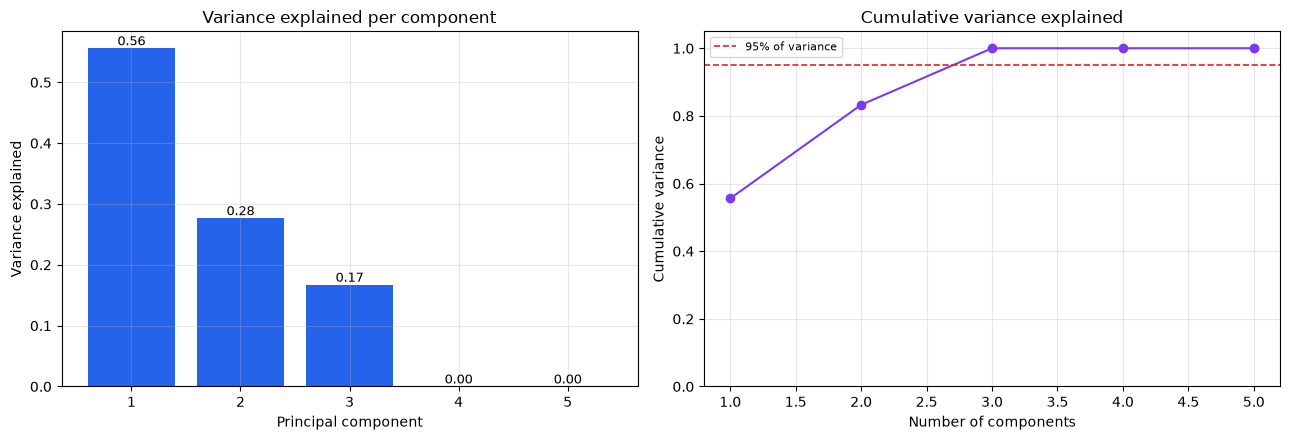

Variance explained per component: [0.556 0.277 0.167 0.    0.   ]

3 of 5 components retain 95% of the variance.


In [19]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

X_pca_input = X_rank[SELECTED_NUMERIC]
X_std = StandardScaler().fit_transform(X_pca_input)

pca = PCA(random_state=RANDOM_STATE).fit(X_std)
explained = pca.explained_variance_ratio_
cumulative = np.cumsum(explained)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
ax.bar(range(1, len(explained) + 1), explained, color="#2563eb")
ax.set_xlabel("Principal component"); ax.set_ylabel("Variance explained")
ax.set_title("Variance explained per component")
for i, v in enumerate(explained):
    ax.text(i + 1, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9)

ax = axes[1]
ax.plot(range(1, len(cumulative) + 1), cumulative, "o-", color="#7c3aed")
ax.axhline(0.95, color="#dc2626", ls="--", lw=1.2, label="95% of variance")
ax.set_xlabel("Number of components"); ax.set_ylabel("Cumulative variance")
ax.set_title("Cumulative variance explained")
ax.set_ylim(0, 1.05); ax.legend(fontsize=8)

plt.tight_layout(); show("06_pca_variance")

n_95 = int(np.searchsorted(cumulative, 0.95) + 1)
print("Variance explained per component:", np.round(explained, 3))
print(f"\n{n_95} of {len(SELECTED_NUMERIC)} components retain 95% of the variance.")

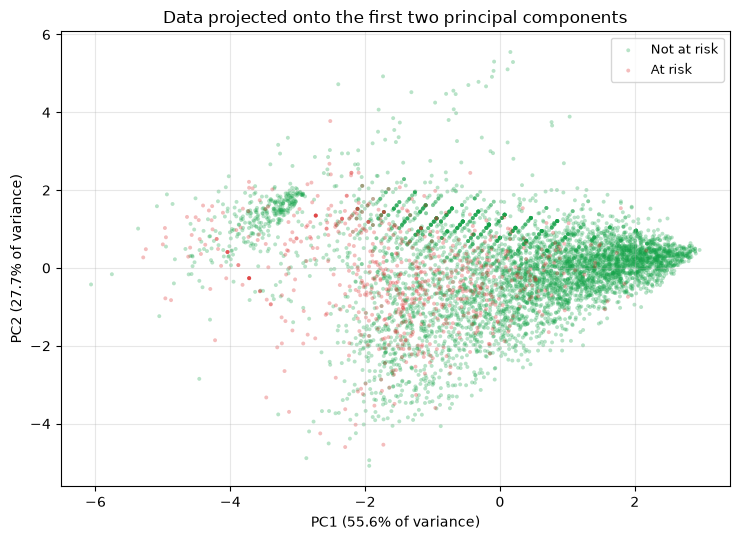

In [20]:
# Project onto the first two components to see whether the classes separate.
coords = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_std)

fig, ax = plt.subplots(figsize=(7.5, 5.5))
for label, colour, name in [(0, "#16a34a", "Not at risk"), (1, "#dc2626", "At risk")]:
    mask = featured["at_risk"].values == label
    ax.scatter(coords[mask, 0], coords[mask, 1], s=8, alpha=0.3,
               color=colour, label=name, edgecolors="none")
ax.set_xlabel(f"PC1 ({explained[0]:.1%} of variance)")
ax.set_ylabel(f"PC2 ({explained[1]:.1%} of variance)")
ax.set_title("Data projected onto the first two principal components")
ax.legend(fontsize=9)
plt.tight_layout(); show("07_pca_projection")

### Is PCA used for the final model? No — and that is a deliberate choice.

PCA is demonstrated because feature extraction and data reduction are part of the
syllabus, and the analysis above is genuinely informative: the first two
components carry 83% of the variance, and the at-risk students concentrate on the
low-PC1 (low marks) side — but they overlap heavily with safe students. No single
straight boundary separates the classes, which already hints that a non-linear model
will be needed (confirmed in section 13).

It is **not** used in the final pipeline, for two reasons:

1. **Almost nothing to gain.** There are only five numeric features. Compressing five columns into three or four saves no meaningful computation.
2. **Interpretability is the actual deliverable.** A principal component is a weighted blend of all five inputs. "PC1 is high" cannot be explained to a student or a teacher, whereas "attendance is 58% and the midterm dropped 20 marks" can. For a system whose purpose is prompting human intervention, an explanation the human can act on matters more than a marginal accuracy gain.

Knowing when *not* to apply a technique is part of using it correctly.

---
# 11. Feature scaling — normalization and standardization

Both methods required by the syllabus, with the difference made explicit.

| Method | Formula | Output range | Best for |
|---|---|---|---|
| **Normalization** (`MinMaxScaler`) | `(x - min) / (max - min)` | `[0, 1]` | bounded inputs; distance-based methods |
| **Standardization** (`StandardScaler`) | `(x - mean) / std` | mean 0, std 1 | linear models; anything assuming roughly Gaussian inputs |

### Why scaling is needed at all

Logistic Regression optimises a weighted sum of the inputs. A feature ranging
0-100 contributes far larger gradients than one ranging -30 to +30, so it
dominates the fit for reasons of *units* rather than *importance*. Standardising
puts every feature on comparable footing.

### Where it is deliberately not applied

**Tree models are not scaled.** Decision trees and random forests split on
thresholds (`midterm_marks <= 47.5`), and any monotonic rescaling produces the
identical split. Scaling them changes nothing. Scaling a tree and then claiming
it was necessary would misrepresent why scaling exists — so the pipelines in
section 13 scale the linear models only.

In [21]:
from sklearn.preprocessing import MinMaxScaler

sample = X_rank[SELECTED_NUMERIC]
normalized   = pd.DataFrame(MinMaxScaler().fit_transform(sample),   columns=SELECTED_NUMERIC)
standardized = pd.DataFrame(StandardScaler().fit_transform(sample), columns=SELECTED_NUMERIC)

comparison = pd.DataFrame({
    "raw_min":  sample.min(),          "raw_max":  sample.max(),
    "norm_min": normalized.min(),      "norm_max": normalized.max(),
    "std_mean": standardized.mean(),   "std_std":  standardized.std(),
})
print("Effect of each scaler:\n")
print(comparison.round(2).to_string())

Effect of each scaler:

                          raw_min  raw_max  norm_min  norm_max  std_mean  std_std
attendance_percentage        0.00   100.00       0.0       1.0      -0.0      1.0
internal_marks               0.00   100.00       0.0       1.0       0.0      1.0
midterm_marks                0.00   100.00       0.0       1.0       0.0      1.0
internal_midterm_average     0.00   100.00       0.0       1.0      -0.0      1.0
performance_trend          -82.78    81.67       0.0       1.0      -0.0      1.0


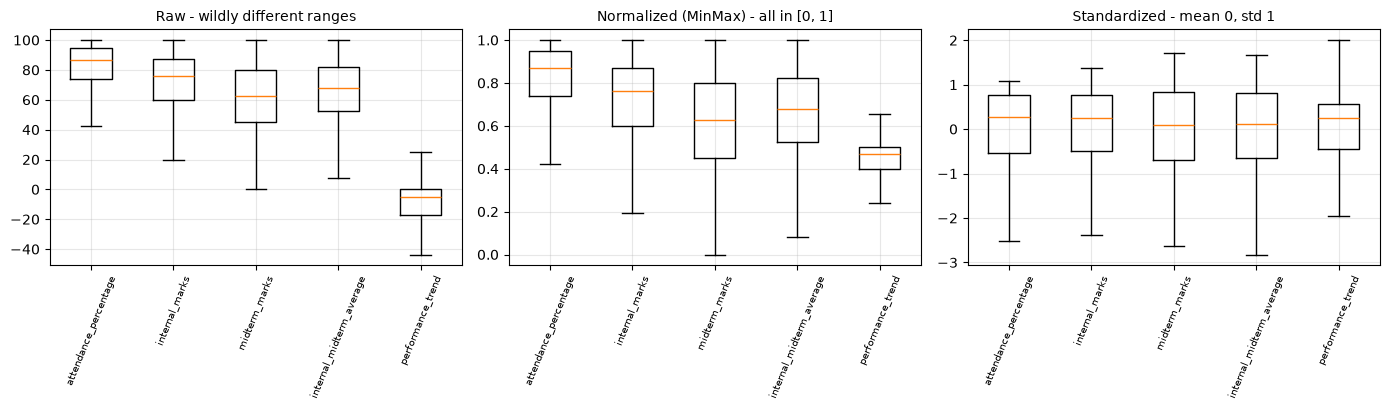

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, data, title in [
    (axes[0], sample,       "Raw - wildly different ranges"),
    (axes[1], normalized,   "Normalized (MinMax) - all in [0, 1]"),
    (axes[2], standardized, "Standardized - mean 0, std 1"),
]:
    ax.boxplot([data[c] for c in SELECTED_NUMERIC], tick_labels=SELECTED_NUMERIC,
               orientation="vertical", showfliers=False)
    ax.set_title(title, fontsize=10)
    ax.tick_params(axis="x", rotation=68, labelsize=7.5)
plt.tight_layout(); show("08_scaling_comparison")

---
# 12. Preparation of the training and testing datasets

The final step of the CE syllabus, and the one that makes evaluation meaningful.

### Why split at all

A model evaluated on the same rows it learned from is graded on memorisation. The
test set is held back so the reported numbers describe performance on data the
model has never seen.

### Why stratify

Roughly 10% of students are at risk. A random split could easily land a very
different proportion in the test set — or, with a small enough test set, almost
none at all. `stratify=y` forces both splits to preserve the class ratio.

### Why the preprocessing lives inside a Pipeline

This is the part that is easy to get wrong. If the imputer and scaler were fitted
on the whole dataset before splitting, the training data would carry information
from the test rows — the median and the mean would both have been computed using
them. Metrics would come out optimistically wrong.

Wrapping every step in a `Pipeline` makes the correct behaviour structural:
`fit()` touches training folds only, and `transform()` applies those learned
values to the test set.

In [23]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

X = featured[FEATURES].copy()
y_clf = featured["at_risk"].copy()      # classification target
y_reg = featured["final_marks"].copy()  # regression target

# Preprocessing definition. Nothing is fitted yet - fitting happens inside
# cross-validation and .fit() on the training split only.
numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale",  StandardScaler()),
])
categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe,     SELECTED_NUMERIC),
    ("cat", categorical_pipe, SELECTED_CATEGORICAL),
])

# Tree models need imputing and encoding but NOT scaling (see section 11).
tree_preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), SELECTED_NUMERIC),
    ("cat", categorical_pipe,                 SELECTED_CATEGORICAL),
])

from sklearn.base import clone


def make(prep, model):
    # Every model gets its OWN copy of the preprocessor, so fitting one
    # pipeline can never change another.
    return Pipeline([("prep", clone(prep)), ("model", model)])


print("Feature matrix:", X.shape)
print("Numeric block  :", SELECTED_NUMERIC)
print("Categorical    :", SELECTED_CATEGORICAL)

Feature matrix: (6033, 8)
Numeric block  : ['attendance_percentage', 'internal_marks', 'midterm_marks', 'internal_midterm_average', 'performance_trend']
Categorical    : ['department', 'course_type', 'attendance_band']


In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_clf,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_clf,            # preserve the at-risk ratio in both splits
)

# The regression split reuses the SAME row indices, so both tasks are evaluated
# on identical students and their results stay comparable.
y_train_reg = y_reg.loc[X_train.index]
y_test_reg  = y_reg.loc[X_test.index]

print(f"Training set: {X_train.shape[0]} rows")
print(f"Test set    : {X_test.shape[0]} rows")

print("\nClass balance preserved by stratification:")
balance = pd.DataFrame({
    "train": y_train.value_counts(normalize=True).sort_index().round(4),
    "test":  y_test.value_counts(normalize=True).sort_index().round(4),
    "train_n": y_train.value_counts().sort_index(),
    "test_n":  y_test.value_counts().sort_index(),
})
print(balance.to_string())

Training set: 4826 rows
Test set    : 1207 rows

Class balance preserved by stratification:
          train    test  train_n  test_n
at_risk                                 
0        0.8893  0.8898     4292    1074
1        0.1107  0.1102      534     133


## 12.1 Verifying the pre-processing, and the final dataset

Two checks close out Part A.

**Missing-value verification.** Section 5 identified the missing values and
defined how they would be treated. Because the treatment happens *inside* the
pipeline, it has to be confirmed after fitting rather than before — the check
below proves that no missing values survive into the matrix the model sees.

**The final pre-processed dataset.** This is the deliverable of CE-1: a cleaned,
transformed, analysis-ready dataset. It is shown in two forms — the readable
engineered table, and the fully encoded and scaled numeric matrix that is
actually handed to the model.


In [25]:
# --- Missing-value verification -------------------------------------------
before = X_train.isna().sum()
before = before[before > 0]

fitted = preprocessor.fit(X_train)                 # fitted on TRAINING data only
X_train_processed = fitted.transform(X_train)
X_test_processed  = fitted.transform(X_test)

processed_names = [n.split("__", 1)[-1] for n in fitted.get_feature_names_out()]

print("MISSING VALUES - BEFORE pre-processing (training set)")
print(before.to_string() if len(before) else "  none in the selected features")

remaining = int(np.isnan(X_train_processed).sum())
print(f"\nMISSING VALUES - AFTER pre-processing: {remaining}")
assert remaining == 0, "Imputation failed - missing values survived"
print("Verified: no missing values remain in the model input.")

print(f"\nShape before encoding: {X_train.shape}")
print(f"Shape after encoding : {X_train_processed.shape}"
      f"  ({len(SELECTED_NUMERIC)} numeric + one-hot expansion of "
      f"{len(SELECTED_CATEGORICAL)} categorical)")


MISSING VALUES - BEFORE pre-processing (training set)
  none in the selected features

MISSING VALUES - AFTER pre-processing: 0
Verified: no missing values remain in the model input.

Shape before encoding: (4826, 8)
Shape after encoding : (4826, 17)  (5 numeric + one-hot expansion of 3 categorical)


In [26]:
# --- The final pre-processed dataset ---------------------------------------
# Form 1: the readable engineered table (cleaned + new features + targets)
readable_cols = (["source", "student_id", "course_code"] + FEATURES
                 + ["final_marks", "at_risk"])
final_dataset = featured[readable_cols].copy()

print("FINAL CLEANED + TRANSFORMED DATASET")
print(f"Shape: {final_dataset.shape[0]} rows x {final_dataset.shape[1]} columns")
print(f"Missing values: {int(final_dataset.isna().sum().sum())}")
print(f"Duplicates: {int(final_dataset.duplicated().sum())}\n")
print("Column data types:")
print(final_dataset.dtypes.to_string())
print()
final_dataset.head(10)


FINAL CLEANED + TRANSFORMED DATASET
Shape: 6033 rows x 13 columns
Missing values: 0
Duplicates: 0

Column data types:
source                          str
student_id                      str
course_code                     str
attendance_percentage       float64
internal_marks              float64
midterm_marks               float64
internal_midterm_average    float64
performance_trend           float64
department                      str
course_type                  object
attendance_band              object
final_marks                 float64
at_risk                       int64



,source,student_id,course_code,attendance_percentage,internal_marks,midterm_marks,internal_midterm_average,performance_trend,department,course_type,attendance_band,final_marks,at_risk
0,UCI,UCIMAT1010000,MAT101,90.00,25.0,30.0,27.5,5.0,MAT,MANDATORY,SAFE,30.0,1
1,UCI,UCIMAT1010001,MAT101,93.33,25.0,25.0,25.0,0.0,MAT,MANDATORY,SAFE,30.0,1
2,UCI,UCIMAT1010002,MAT101,83.33,35.0,40.0,37.5,5.0,MAT,MANDATORY,SAFE,50.0,0
3,UCI,UCIMAT1010003,MAT101,96.67,75.0,70.0,72.5,-5.0,MAT,MANDATORY,SAFE,75.0,0
4,UCI,UCIMAT1010004,MAT101,93.33,30.0,50.0,40.0,20.0,MAT,MANDATORY,SAFE,50.0,0
5,UCI,UCIMAT1010005,MAT101,83.33,75.0,75.0,75.0,0.0,MAT,MANDATORY,SAFE,75.0,0
6,UCI,UCIMAT1010006,MAT101,100.00,60.0,60.0,60.0,0.0,MAT,MANDATORY,SAFE,55.0,0
7,UCI,UCIMAT1010007,MAT101,90.00,30.0,25.0,27.5,-5.0,MAT,MANDATORY,SAFE,30.0,1
8,UCI,UCIMAT1010008,MAT101,100.00,80.0,90.0,85.0,10.0,MAT,MANDATORY,SAFE,95.0,0
9,UCI,UCIMAT1010009,MAT101,100.00,70.0,75.0,72.5,5.0,MAT,MANDATORY,SAFE,75.0,0


In [27]:
# Form 2: the fully encoded + scaled numeric matrix the model actually receives
processed_preview = pd.DataFrame(X_train_processed, columns=processed_names)

print("MODEL INPUT MATRIX (encoded + scaled, training split)")
print(f"Shape: {processed_preview.shape[0]} rows x {processed_preview.shape[1]} columns\n")
print("Numeric columns are standardised - mean ~0, std ~1:")
print(processed_preview[SELECTED_NUMERIC].agg(["mean", "std"]).round(3).to_string())
print()
processed_preview.head(8).round(3)


MODEL INPUT MATRIX (encoded + scaled, training split)
Shape: 4826 rows x 17 columns

Numeric columns are standardised - mean ~0, std ~1:
      attendance_percentage  internal_marks  midterm_marks  internal_midterm_average  performance_trend
mean                    0.0            -0.0           -0.0                      -0.0                0.0
std                     1.0             1.0            1.0                       1.0                1.0



,attendance_percentage,internal_marks,midterm_marks,internal_midterm_average,performance_trend,department_CCC,department_CSE,department_DDD,department_ECE,department_MAT,department_POR,course_type_ELECTIVE,course_type_MANDATORY,course_type_NOT_RECORDED,attendance_band_CRITICAL,attendance_band_SAFE,attendance_band_WARNING
0,-2.124,-0.067,-1.404,-0.821,-1.789,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
1,1.089,0.736,0.973,0.930,0.378,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
2,0.018,0.745,-0.207,0.275,-1.207,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
3,0.196,-0.615,-0.835,-0.790,-0.345,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
4,0.553,-1.059,-0.672,-0.932,0.426,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
5,0.760,0.551,-0.231,0.160,-0.996,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
6,0.776,-1.644,-1.114,-1.486,0.567,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
7,0.881,-1.412,-0.680,-1.121,0.857,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0


---
# 13. Classification — at-risk detection

Six algorithms, chosen to cover every classification family in the syllabus:

| Algorithm | How it decides | Why it is here |
|---|---|---|
| **Logistic Regression** | a weighted sum of the features passed through a sigmoid gives P(at risk) | the linear baseline; its coefficients are directly explainable |
| **K-Nearest Neighbours** | looks at the *k* most similar students and takes a vote | instance-based — no training, all the work at prediction time |
| **Naive Bayes** | Bayes' theorem, assuming features are independent given the class | probabilistic and very fast; the independence assumption is tested here, because internal and midterm marks are clearly *not* independent |
| **Support Vector Machine** | finds the widest-margin boundary; the RBF kernel lets it curve | strong on mid-sized data with non-linear boundaries |
| **Decision Tree** | a sequence of yes/no threshold questions | non-linear and readable as a flowchart |
| **Random Forest** | hundreds of trees on random subsets, majority vote | an ensemble; usually the strongest, at a cost in interpretability |

The distance- and margin-based models (KNN, SVM) and the linear model receive
**standardised** inputs; the tree models do not need them (section 11).

### The metric that decides — recall, then F2

The classes are imbalanced (~11% at risk). A model that predicts "not at risk"
for **every single student** would score about 89% accuracy while identifying
nobody. Accuracy is actively misleading here.

The two errors are not symmetric:

- **False negative** — a genuinely at-risk student is marked safe, gets no support, and fails. The harm is real and lands on the student.
- **False positive** — a safe student is flagged, a teacher reviews the case, nothing is wrong. The cost is a few minutes.

So **recall on the at-risk class** is what matters most. But recall alone can be
gamed — flag *every* student and recall is a perfect 1.0. Models are therefore
ranked by **F2**, the F-score that weights recall **twice** as heavily as precision:

```
F2 = 5 · precision · recall / (4 · precision + recall)
```

F2 keeps recall in charge while still charging the model for a flood of false
alarms. `class_weight="balanced"` tells the models that support it to weight the
minority class accordingly; KNN and Naive Bayes have no such option, and the
results show what that costs.

In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
    confusion_matrix, classification_report, roc_auc_score,
)

classifiers = {
    "Logistic Regression": make(preprocessor, LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)),
    "K-Nearest Neighbours": make(preprocessor, KNeighborsClassifier(
        n_neighbors=15, weights="distance")),
    "Naive Bayes": make(preprocessor, GaussianNB()),
    "SVM (RBF kernel)": make(preprocessor, SVC(
        kernel="rbf", C=1.0, class_weight="balanced", probability=True,
        random_state=RANDOM_STATE)),
    "Decision Tree": make(tree_preprocessor, DecisionTreeClassifier(
        max_depth=5, class_weight="balanced", random_state=RANDOM_STATE)),
    "Random Forest": make(tree_preprocessor, RandomForestClassifier(
        n_estimators=300, max_depth=8, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1)),
}


def clf_metrics(y_true, pred, proba=None):
    y_true, pred = np.asarray(y_true), np.asarray(pred)
    return {
        "Accuracy":  accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall":    recall_score(y_true, pred, zero_division=0),
        "F1":        f1_score(y_true, pred, zero_division=0),
        "F2":        fbeta_score(y_true, pred, beta=2, zero_division=0),
        "ROC-AUC":   roc_auc_score(y_true, proba) if proba is not None else np.nan,
        "Missed":    int(((y_true == 1) & (pred == 0)).sum()),
    }


clf_results, clf_predictions = [], {}
for name, pipe in classifiers.items():
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    clf_predictions[name] = (pred, proba)
    clf_results.append({"Model": name, **clf_metrics(y_test, pred, proba)})

clf_table = pd.DataFrame(clf_results).set_index("Model").round(3)
print(f"Classification results on the held-out test set "
      f"({len(y_test)} students, {int(y_test.sum())} at risk):\n")
print(clf_table.to_string())

C:\Users\pavit\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Classification results on the held-out test set (1207 students, 133 at risk):

                      Accuracy  Precision  Recall     F1     F2  ROC-AUC  Missed
Model                                                                           
Logistic Regression      0.728      0.254   0.759  0.381  0.544    0.819      32
K-Nearest Neighbours     0.891      0.511   0.173  0.258  0.199    0.805     110
Naive Bayes              0.115      0.111   1.000  0.199  0.384    0.788       0
SVM (RBF kernel)         0.732      0.271   0.842  0.410  0.592    0.853      21
Decision Tree            0.732      0.270   0.842  0.409  0.591    0.841      21
Random Forest            0.766      0.299   0.835  0.440  0.615    0.875      22


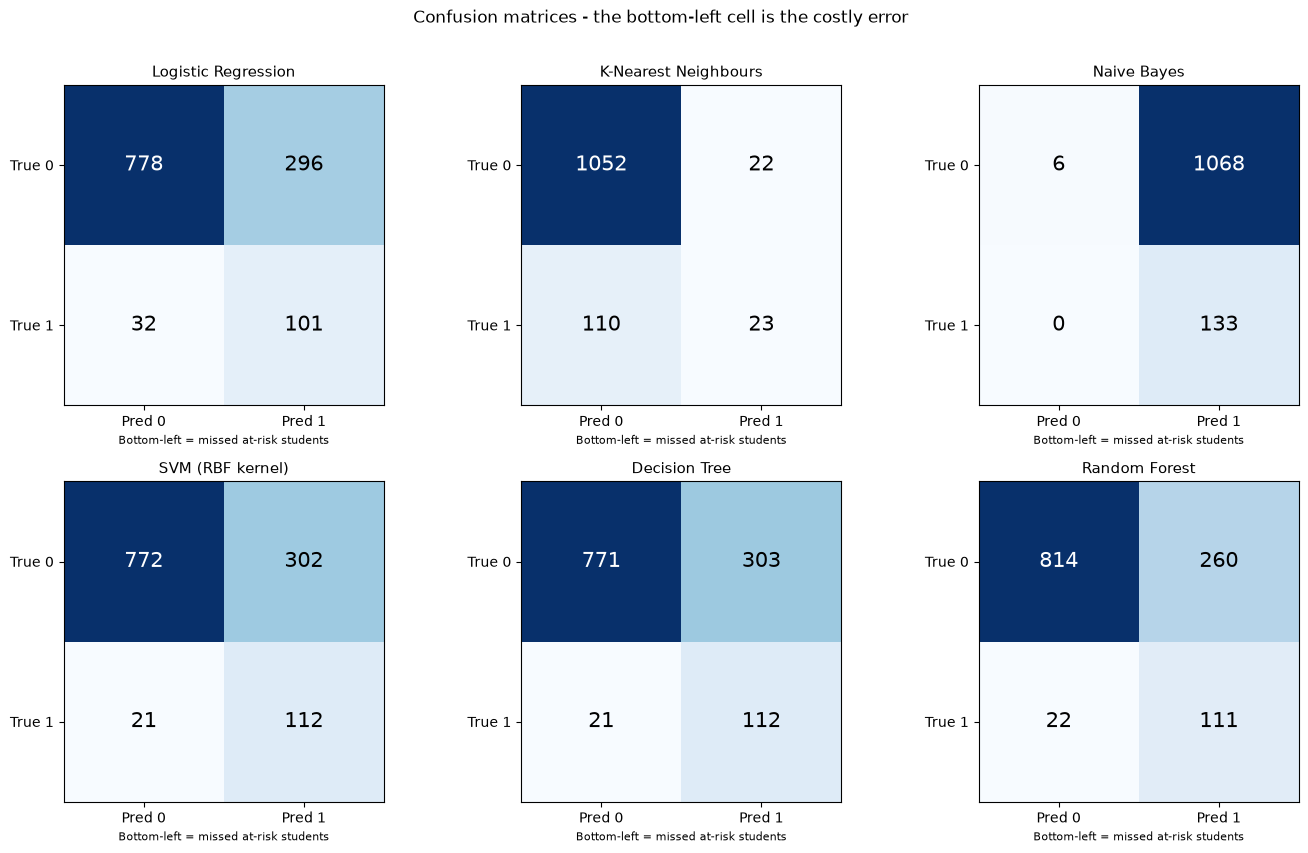

Highest F2 on the test set: Random Forest

Detailed report - Random Forest:

              precision    recall  f1-score   support

 Not at risk       0.97      0.76      0.85      1074
     At risk       0.30      0.83      0.44       133

    accuracy                           0.77      1207
   macro avg       0.64      0.80      0.65      1207
weighted avg       0.90      0.77      0.81      1207



In [29]:
n_models = len(clf_predictions)
fig, axes = plt.subplots(2, 3, figsize=(14, 8.4))

for ax, (name, (pred, _)) in zip(axes.ravel(), clf_predictions.items()):
    cm = confusion_matrix(y_test, pred)
    ax.imshow(cm, cmap="Blues")
    ax.set_title(name, fontsize=11)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Pred 0", "Pred 1"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["True 0", "True 1"])
    ax.grid(False)
    total = cm.sum()
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}", ha="center", va="center", fontsize=15,
                    color="white" if cm[i, j] > total * 0.3 else "black")
    ax.set_xlabel("Bottom-left = missed at-risk students", fontsize=8)

for ax in axes.ravel()[n_models:]:
    ax.axis("off")

plt.suptitle("Confusion matrices - the bottom-left cell is the costly error", y=1.01)
plt.tight_layout(); show("09_confusion_matrices")

best_f2_name = clf_table["F2"].idxmax()
print(f"Highest F2 on the test set: {best_f2_name}")
print(f"\nDetailed report - {best_f2_name}:\n")
print(classification_report(y_test, clf_predictions[best_f2_name][0],
                            target_names=["Not at risk", "At risk"], zero_division=0))

**Observations (test set: 1,207 students, 133 at risk).**

- **Random Forest** has the best balance: F2 = 0.615, ROC-AUC = 0.875, recall 0.835 (missed 22 of 133).
- **SVM** and the **Decision Tree** are close behind (F2 ≈ 0.59, 21 missed each).
- **Logistic Regression** misses 32 — a straight-line boundary cannot fit how the classes overlap.
- **Naive Bayes is the textbook trap.** Recall is a perfect **1.000** — it missed nobody — but accuracy is **0.115**: it flagged almost every student as at risk. The independence assumption fails badly here (internal, midterm and their average are strongly correlated), so its probabilities are badly calibrated. This is exactly why recall alone cannot be the selection metric, and why F2 is used.
- **KNN** has the *highest* accuracy (0.891) and the *lowest* recall (0.173), missing 110 of 133. It has no `class_weight` option, so in any neighbourhood the majority "not at risk" class out-votes the minority. High accuracy, useless model — the imbalance trap from the other side.
- Every model's precision is modest (~0.3): to catch most at-risk students, roughly two safe students are also flagged for each real one. For a "teacher takes a look" intervention, that trade is acceptable (section 13).

---
# 14. Regression — predicting final marks

The same features, a continuous target. Three models, each one step more flexible:

| Model | Form | Why it is here |
|---|---|---|
| **Multiple Linear Regression** | `final = b0 + b1·x1 + ... + bn·xn` | the baseline — one straight-line effect per feature |
| **Polynomial Regression (degree 2)** | adds every square and pairwise product of the features, then fits linearly | captures curvature and interactions (e.g. low attendance *and* a falling trend) |
| **Random Forest Regressor** | averages hundreds of regression trees | non-linear without choosing the curve shape by hand |

| Metric | Meaning |
|---|---|
| **MAE** | Average error in marks. Directly readable: "typically wrong by N marks." |
| **MSE** | Mean squared error; punishes large misses more heavily. |
| **RMSE** | Square root of MSE, back in marks. Comparable to MAE but outlier-sensitive. |
| **R²** | Share of variance explained. 1.0 is perfect; 0.0 is no better than always predicting the mean. |

In [30]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

regressors = {
    "Multiple Linear Regression": make(preprocessor, LinearRegression()),
    "Polynomial Regression (deg 2)": Pipeline([
        ("prep", clone(preprocessor)),
        ("poly", PolynomialFeatures(degree=2, include_bias=False)),
        ("model", LinearRegression()),
    ]),
    "Random Forest Regressor": make(tree_preprocessor, RandomForestRegressor(
        n_estimators=300, max_depth=12, random_state=RANDOM_STATE, n_jobs=-1)),
}


def reg_metrics(y_true, pred):
    mse = mean_squared_error(y_true, pred)
    return {"MAE": mean_absolute_error(y_true, pred), "MSE": mse,
            "RMSE": np.sqrt(mse), "R2": r2_score(y_true, pred)}


reg_results, reg_predictions = [], {}
for name, pipe in regressors.items():
    pipe.fit(X_train, y_train_reg)
    pred = pipe.predict(X_test)
    reg_predictions[name] = pred
    reg_results.append({"Model": name, **reg_metrics(y_test_reg, pred)})

reg_table = pd.DataFrame(reg_results).set_index("Model").round(3)
print("Regression results on the held-out test set:\n")
print(reg_table.to_string())

Regression results on the held-out test set:

                                  MAE      MSE    RMSE     R2
Model                                                        
Multiple Linear Regression     13.088  285.188  16.888  0.350
Polynomial Regression (deg 2)  11.411  225.805  15.027  0.485
Random Forest Regressor        11.116  213.223  14.602  0.514


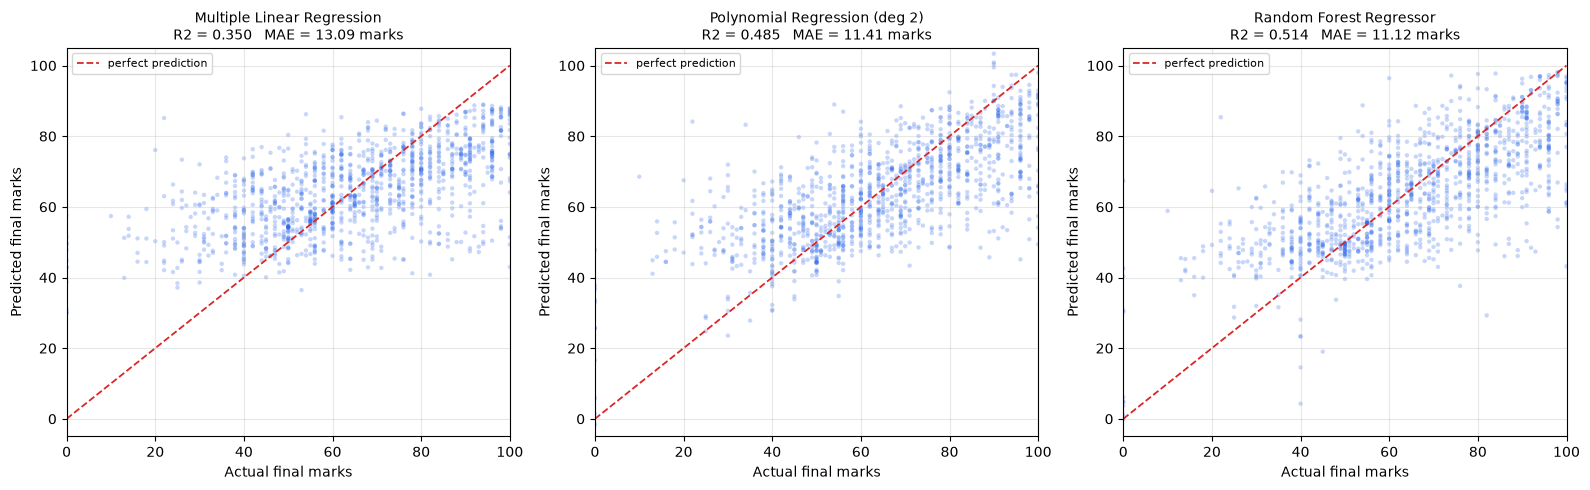

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, pred) in zip(axes, reg_predictions.items()):
    ax.scatter(y_test_reg, pred, alpha=0.25, s=10, color="#2563eb", edgecolors="none")
    ax.plot([0, 100], [0, 100], "--", color="#dc2626", lw=1.3, label="perfect prediction")
    ax.set_xlabel("Actual final marks"); ax.set_ylabel("Predicted final marks")
    r2 = r2_score(y_test_reg, pred); mae = mean_absolute_error(y_test_reg, pred)
    ax.set_title(f"{name}\nR2 = {r2:.3f}   MAE = {mae:.2f} marks", fontsize=10)
    ax.set_xlim(0, 100); ax.set_ylim(-5, 105); ax.legend(fontsize=8)

plt.tight_layout(); show("10_regression_actual_vs_predicted")

**Observations.**

- **Random Forest** is the most accurate: MAE 11.1 marks, R² 0.514.
- **Polynomial regression (degree 2)** improves substantially on the straight line (R² 0.35 → 0.49): the relationship has curvature and interactions that a single linear term per feature cannot express.
- **Multiple Linear Regression** is the weakest (R² 0.35).

**Why R² dropped from 0.88 (CE-1) to ~0.51.** The CE-1 figure came almost entirely from UCI, where
the final grade is nearly a copy of the midterm. OULAD's final is an independent exam (section 6),
and the scatter plots above show the result: a wide band of students whose final exam fell far
below their coursework. The error is concentrated there — section 22 shows the MAE is about 5
marks on UCI students but about 12 on OULAD students. A lower R² on harder, more realistic data is
a more trustworthy number than a high R² on an easy one.

---
# 15. Model comparison

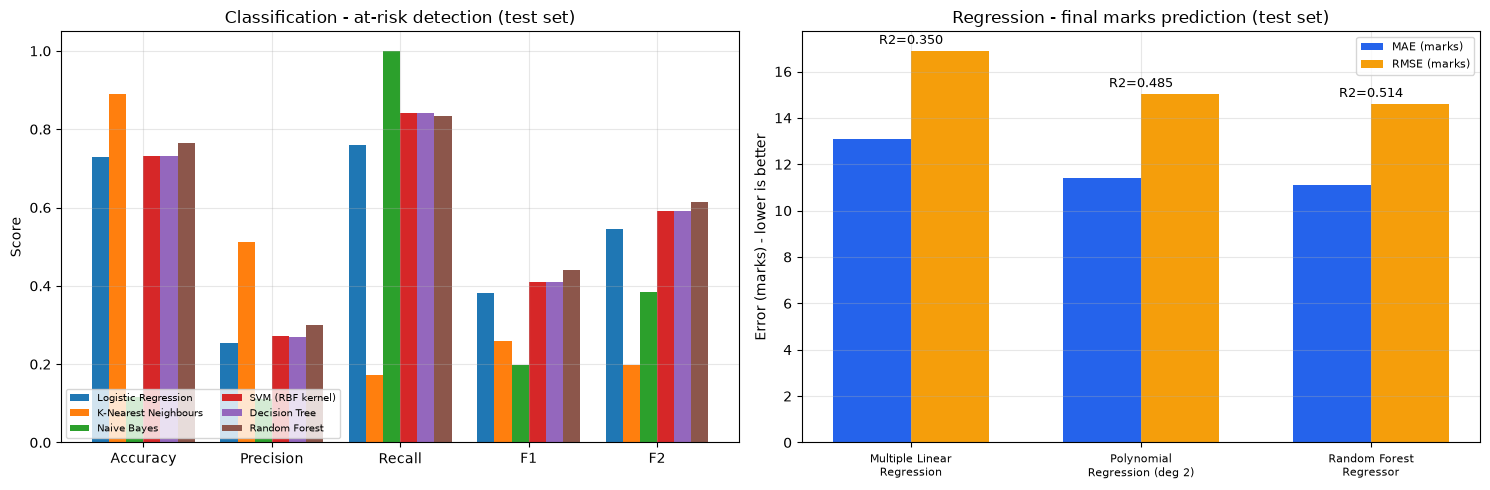

CLASSIFICATION

                      Accuracy  Precision  Recall     F1     F2  ROC-AUC  Missed
Model                                                                           
Logistic Regression      0.728      0.254   0.759  0.381  0.544    0.819      32
K-Nearest Neighbours     0.891      0.511   0.173  0.258  0.199    0.805     110
Naive Bayes              0.115      0.111   1.000  0.199  0.384    0.788       0
SVM (RBF kernel)         0.732      0.271   0.842  0.410  0.592    0.853      21
Decision Tree            0.732      0.270   0.842  0.409  0.591    0.841      21
Random Forest            0.766      0.299   0.835  0.440  0.615    0.875      22


REGRESSION

                                  MAE      MSE    RMSE     R2
Model                                                        
Multiple Linear Regression     13.088  285.188  16.888  0.350
Polynomial Regression (deg 2)  11.411  225.805  15.027  0.485
Random Forest Regressor        11.116  213.223  14.602  0.514


In [32]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Classification
ax = axes[0]
metrics = ["Accuracy", "Precision", "Recall", "F1", "F2"]
k = len(clf_table); width = 0.8 / k; xs = np.arange(len(metrics))
for i, (name, row) in enumerate(clf_table.iterrows()):
    ax.bar(xs + (i - (k - 1) / 2) * width, [row[m] for m in metrics], width, label=name)
ax.set_xticks(xs); ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.05); ax.set_ylabel("Score")
ax.set_title("Classification - at-risk detection (test set)")
ax.legend(fontsize=7, loc="lower left", ncol=2)

# Regression
ax = axes[1]
names = list(reg_table.index)
xs = np.arange(len(names)); width = 0.34
ax.bar(xs - width/2, reg_table["MAE"],  width, label="MAE (marks)",  color="#2563eb")
ax.bar(xs + width/2, reg_table["RMSE"], width, label="RMSE (marks)", color="#f59e0b")
for i, name in enumerate(names):
    ax.text(i, max(reg_table.loc[name, "RMSE"], reg_table.loc[name, "MAE"]) + 0.3,
            f"R2={reg_table.loc[name, 'R2']:.3f}", ha="center", fontsize=9)
ax.set_xticks(xs)
ax.set_xticklabels([n.replace(" Regress", "\nRegress") for n in names], fontsize=8)
ax.set_ylabel("Error (marks) - lower is better")
ax.set_title("Regression - final marks prediction (test set)")
ax.legend(fontsize=8)

plt.tight_layout(); show("11_model_comparison")

print("CLASSIFICATION\n"); print(clf_table.to_string())
print("\n\nREGRESSION\n");  print(reg_table.to_string())

---
# 16. Does machine learning actually beat the ERP's existing rule?

This is the question that justifies the whole project, and it deserves a direct
answer rather than an assumption.

The ERP **already** predicts final grades, in `server/lib/timetableInsights.js`.
It applies fixed weights — `INTERNAL 0.2`, `MID_TERM 0.3`, `FINAL 0.5` — and when
the final is unknown it substitutes the average of the components entered so far.

Substituting `final = (internal + midterm) / 2` and simplifying:

```
projected = 0.2·I + 0.3·M + 0.5·((I + M)/2)
          = 0.45·I + 0.55·M
```

So the existing system is a fixed linear rule on two inputs. It ignores
attendance entirely. Below it is evaluated on **exactly the same test set** as
the ML models — the only fair comparison.

In [33]:
# The ERP's existing rule, reimplemented exactly (server/lib/timetableInsights.js)
def erp_rule_predict(frame):
    internal = frame["internal_marks"].astype(float)
    midterm  = frame["midterm_marks"].astype(float)
    current_average = (internal + midterm) / 2.0
    return (0.2 * internal) + (0.3 * midterm) + (0.5 * current_average)


rule_pred_marks = erp_rule_predict(X_test)
rule_pred_risk = (rule_pred_marks < AT_RISK_THRESHOLD).astype(int)

# Regression comparison
rule_mse = mean_squared_error(y_test_reg, rule_pred_marks)
baseline_reg = pd.DataFrame([
    {"Model": "ERP rule (0.45*I + 0.55*M)",
     "MAE":  mean_absolute_error(y_test_reg, rule_pred_marks),
     "MSE":  rule_mse,
     "RMSE": np.sqrt(rule_mse),
     "R2":   r2_score(y_test_reg, rule_pred_marks)},
]).set_index("Model")

reg_vs_rule = pd.concat([baseline_reg, reg_table]).round(3)
print("REGRESSION - ERP rule vs machine learning\n")
print(reg_vs_rule.to_string())

REGRESSION - ERP rule vs machine learning

                                  MAE      MSE    RMSE     R2
Model                                                        
ERP rule (0.45*I + 0.55*M)     13.729  379.355  19.477  0.135
Multiple Linear Regression     13.088  285.188  16.888  0.350
Polynomial Regression (deg 2)  11.411  225.805  15.027  0.485
Random Forest Regressor        11.116  213.223  14.602  0.514


In [34]:
# Classification comparison on the same test set
baseline_clf = pd.DataFrame([
    {"Model": "ERP rule (projected < 40)", **clf_metrics(y_test, rule_pred_risk)},
]).set_index("Model")

clf_vs_rule = pd.concat([baseline_clf, clf_table]).round(3)
print("CLASSIFICATION - ERP rule vs machine learning\n")
print(clf_vs_rule.to_string())

rule_missed = int(((y_test == 1) & (rule_pred_risk == 0)).sum())
print(f"\nAt-risk students in the test set: {int(y_test.sum())}")
print(f"Missed by the ERP rule          : {rule_missed}")
for name in clf_table.index:
    print(f"Missed by {name:22}: {int(clf_table.loc[name, 'Missed'])}")

CLASSIFICATION - ERP rule vs machine learning

                           Accuracy  Precision  Recall     F1     F2  ROC-AUC  Missed
Model                                                                                
ERP rule (projected < 40)     0.861      0.353   0.316  0.333  0.323      NaN      91
Logistic Regression           0.728      0.254   0.759  0.381  0.544    0.819      32
K-Nearest Neighbours          0.891      0.511   0.173  0.258  0.199    0.805     110
Naive Bayes                   0.115      0.111   1.000  0.199  0.384    0.788       0
SVM (RBF kernel)              0.732      0.271   0.842  0.410  0.592    0.853      21
Decision Tree                 0.732      0.270   0.842  0.409  0.591    0.841      21
Random Forest                 0.766      0.299   0.835  0.440  0.615    0.875      22

At-risk students in the test set: 133
Missed by the ERP rule          : 91
Missed by Logistic Regression   : 32
Missed by K-Nearest Neighbours  : 110
Missed by Naive Bayes       

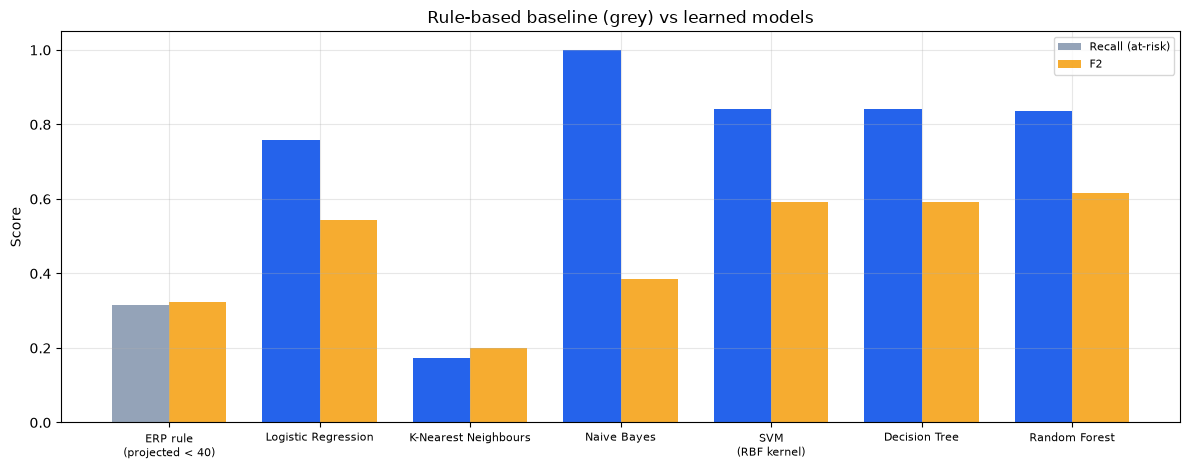

In [35]:
fig, ax = plt.subplots(figsize=(12, 4.8))
models = list(clf_vs_rule.index)
xs = np.arange(len(models)); width = 0.38
colors = ["#94a3b8"] + ["#2563eb"] * (len(models) - 1)

ax.bar(xs - width/2, clf_vs_rule["Recall"], width, label="Recall (at-risk)", color=colors)
ax.bar(xs + width/2, clf_vs_rule["F2"], width, label="F2", color="#f59e0b", alpha=0.85)
ax.set_xticks(xs)
ax.set_xticklabels([m.replace(" (", "\n(") for m in models], fontsize=8)
ax.set_ylim(0, 1.05); ax.set_ylabel("Score")
ax.set_title("Rule-based baseline (grey) vs learned models")
ax.legend(fontsize=8)
plt.tight_layout(); show("12_rule_vs_ml_recall")

**On the three-source data, the ERP's hand-written rule breaks down — and machine learning is
not marginally better, it is decisively better.**

| | ERP rule | Selected ML model (section 19) |
|---|---|---|
| At-risk students missed (of 133) | **91** | **18** |
| Recall | 0.316 | 0.865 |
| Regression R² | 0.135 | 0.529 |

The rule assumes `final ≈ 0.45·internal + 0.55·midterm`. That held for UCI's near-identical
grades, but it badly over-predicts students whose exam falls short of their coursework — exactly
the students who need help. It also ignores attendance completely. A learned model picks up both
effects from the data.

---
# 17. Cross-validation — are the results stable?

Every number so far comes from **one** train/test split. With a test set of this
size, a lucky or unlucky split can move recall by several points — so a single
split is not enough to choose between close models.

**k-fold cross-validation** splits the *training* set into 5 folds. Each model is
trained 5 times — each time on 4 folds, scored on the fifth — so every training
row is used for validation exactly once.

- the **mean** across folds estimates real performance;
- the **standard deviation** says how stable that estimate is;
- `StratifiedKFold` keeps the ~11% at-risk ratio in every fold.

The test set is **not** touched here. It stays reserved for one final check of
the selected model (section 19), so the final reported numbers are still
measured on data no decision was based on.

The table also reports the **training** score. A large gap between training and
cross-validated scores is the signature of overfitting — the subject of section 18.

In [36]:
from sklearn.model_selection import StratifiedKFold, KFold, cross_validate
from sklearn.metrics import make_scorer

f2_scorer = make_scorer(fbeta_score, beta=2, zero_division=0)
cv_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
clf_scoring = {"Recall": "recall", "Precision": "precision", "F1": "f1",
               "F2": f2_scorer, "ROC-AUC": "roc_auc"}

cv_clf_rows, cv_clf_folds = [], {}
for name, pipe in classifiers.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv_clf, scoring=clf_scoring,
                         return_train_score=True, n_jobs=-1)
    cv_clf_folds[name] = res
    row = {"Model": name}
    for m in clf_scoring:
        row[f"{m}"] = res[f"test_{m}"].mean()
        row[f"{m} std"] = res[f"test_{m}"].std()
    row["Train F2"] = res["train_F2"].mean()
    row["Overfit gap"] = row["Train F2"] - row["F2"]
    cv_clf_rows.append(row)

cv_clf_table = pd.DataFrame(cv_clf_rows).set_index("Model").round(3)
print("5-fold stratified cross-validation on the training set (mean across folds):\n")
print(cv_clf_table[["Recall", "Recall std", "Precision", "F1", "F2", "F2 std",
                    "ROC-AUC", "Train F2", "Overfit gap"]].to_string())

5-fold stratified cross-validation on the training set (mean across folds):

                      Recall  Recall std  Precision     F1     F2  F2 std  ROC-AUC  Train F2  Overfit gap
Model                                                                                                    
Logistic Regression    0.738       0.038      0.247  0.370  0.528   0.018    0.791     0.537        0.009
K-Nearest Neighbours   0.116       0.020      0.445  0.184  0.136   0.023    0.809     0.988        0.851
Naive Bayes            1.000       0.000      0.111  0.200  0.385   0.001    0.766     0.385        0.000
SVM (RBF kernel)       0.833       0.033      0.271  0.409  0.589   0.023    0.848     0.616        0.027
Decision Tree          0.835       0.021      0.265  0.402  0.583   0.023    0.811     0.619        0.036
Random Forest          0.794       0.028      0.294  0.429  0.592   0.020    0.850     0.723        0.131


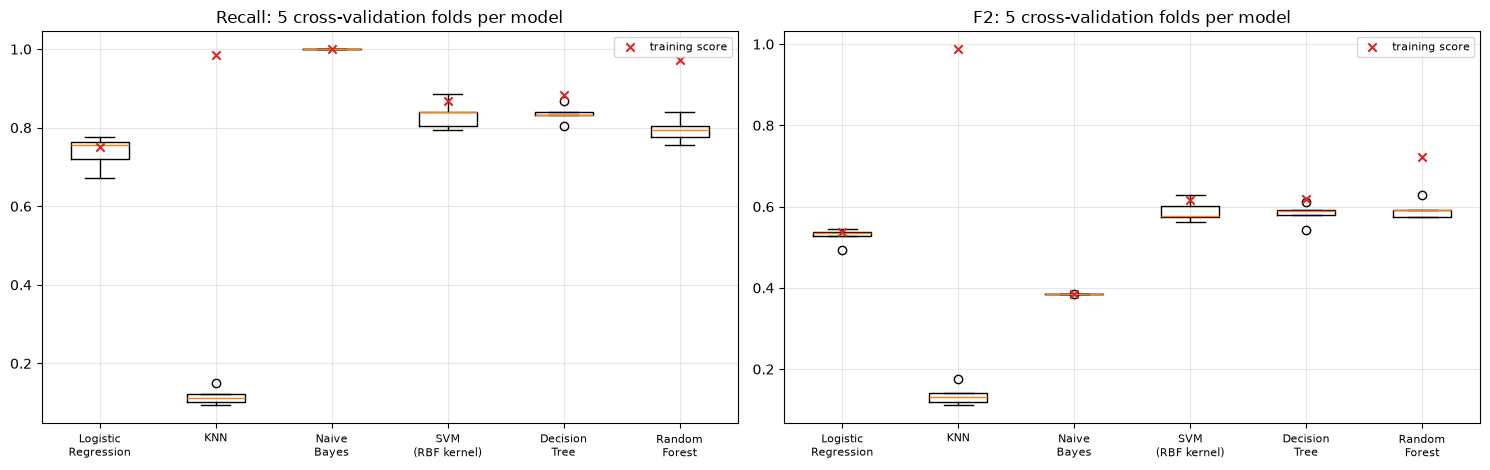

In [37]:
names = list(classifiers)
labels = [n.replace("K-Nearest Neighbours", "KNN").replace(" (", "\n(").replace("Logistic Regression", "Logistic\nRegression")
          .replace("Random Forest", "Random\nForest").replace("Decision Tree", "Decision\nTree").replace("Naive Bayes", "Naive\nBayes")
          for n in names]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, m in zip(axes, ["Recall", "F2"]):
    ax.boxplot([cv_clf_folds[n][f"test_{m}"] for n in names], tick_labels=labels)
    ax.scatter(np.arange(1, len(names) + 1), [cv_clf_folds[n][f"train_{m}"].mean() for n in names],
               marker="x", color="#dc2626", zorder=3, label="training score")
    ax.set_title(f"{m}: 5 cross-validation folds per model")
    ax.tick_params(axis="x", labelsize=8); ax.legend(fontsize=8)
plt.tight_layout(); show("13_cross_validation")

In [38]:
cv_reg = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
reg_scoring = {"MAE": "neg_mean_absolute_error",
               "RMSE": "neg_root_mean_squared_error", "R2": "r2"}

cv_reg_rows = []
for name, pipe in regressors.items():
    res = cross_validate(pipe, X_train, y_train_reg, cv=cv_reg, scoring=reg_scoring,
                         return_train_score=True, n_jobs=-1)
    cv_reg_rows.append({
        "Model": name,
        "MAE": -res["test_MAE"].mean(),
        "RMSE": -res["test_RMSE"].mean(), "RMSE std": res["test_RMSE"].std(),
        "R2": res["test_R2"].mean(), "R2 std": res["test_R2"].std(),
        "Train R2": res["train_R2"].mean(),
        "Overfit gap": res["train_R2"].mean() - res["test_R2"].mean(),
    })

cv_reg_table = pd.DataFrame(cv_reg_rows).set_index("Model").round(3)
print("5-fold cross-validation, regression (training set):\n")
print(cv_reg_table.to_string())

5-fold cross-validation, regression (training set):

                                  MAE    RMSE  RMSE std     R2  R2 std  Train R2  Overfit gap
Model                                                                                        
Multiple Linear Regression     13.137  16.978     0.481  0.317   0.018     0.321        0.003
Polynomial Regression (deg 2)  11.634  15.169     0.255  0.455   0.016     0.466        0.012
Random Forest Regressor        10.756  14.333     0.150  0.513   0.021     0.799        0.286


**What cross-validation adds.**

- **The ranking holds.** Random Forest (F2 0.592), SVM (0.589) and Decision Tree (0.583) lead; Logistic Regression (0.528), Naive Bayes (0.385) and KNN (0.136) trail — the same order as the single test split, so section 13's conclusions were not a lucky split.
- **The results are stable.** F2 varies by only about ±0.02 between folds for every serious model.
- **Overfitting shows up in the train-vs-CV gap** (red ✕ vs box in the figure):
  - **KNN**: training F2 0.988 vs CV 0.136 — a gap of **0.85**. With `weights="distance"`, every training student is its own nearest neighbour at distance zero, so the model memorises the training set perfectly. Classic high variance.
  - **Random Forest**: a moderate gap (0.13) — some memorisation, but its CV score is still the best. Section 19 tunes it to reduce the gap.
  - **Logistic Regression, Naive Bayes**: gap ≈ 0. They are too simple to memorise — but their CV scores are also low. That is high bias (underfitting), not a virtue.
- **Regression:** Random Forest has the best CV RMSE (14.3) but a train R² of 0.80 against CV 0.51 — it overfits; the linear models do not overfit but underfit (CV R² 0.32).

---
# 18. Overfitting, underfitting and the bias-variance trade-off

Every model has a **complexity** setting. Turning it up has two opposite effects:

| | Too simple | Just right | Too complex |
|---|---|---|---|
| Name | **underfitting** | — | **overfitting** |
| Error source | high **bias** — the model cannot represent the pattern | balanced | high **variance** — the model memorises noise in its training rows |
| Training score | poor | good | excellent |
| Validation score | poor | **best** | poor, and falling |

The tell-tale sign of overfitting is a training score that keeps climbing while the
validation score stalls or drops. Three experiments make this visible, each varying
one complexity knob while everything else stays fixed:

1. **Decision Tree `max_depth`** — a deeper tree asks more questions and can isolate individual students.
2. **KNN `k`** — counter-intuitively, *small* k is the complex end: `k = 1` copies the label of the single nearest student.
3. **Polynomial degree** — each extra degree multiplies the number of terms.

Scores come from 5-fold cross-validation on the training set (`validation_curve`).
Then **learning curves** answer a different question: would *more data* help?

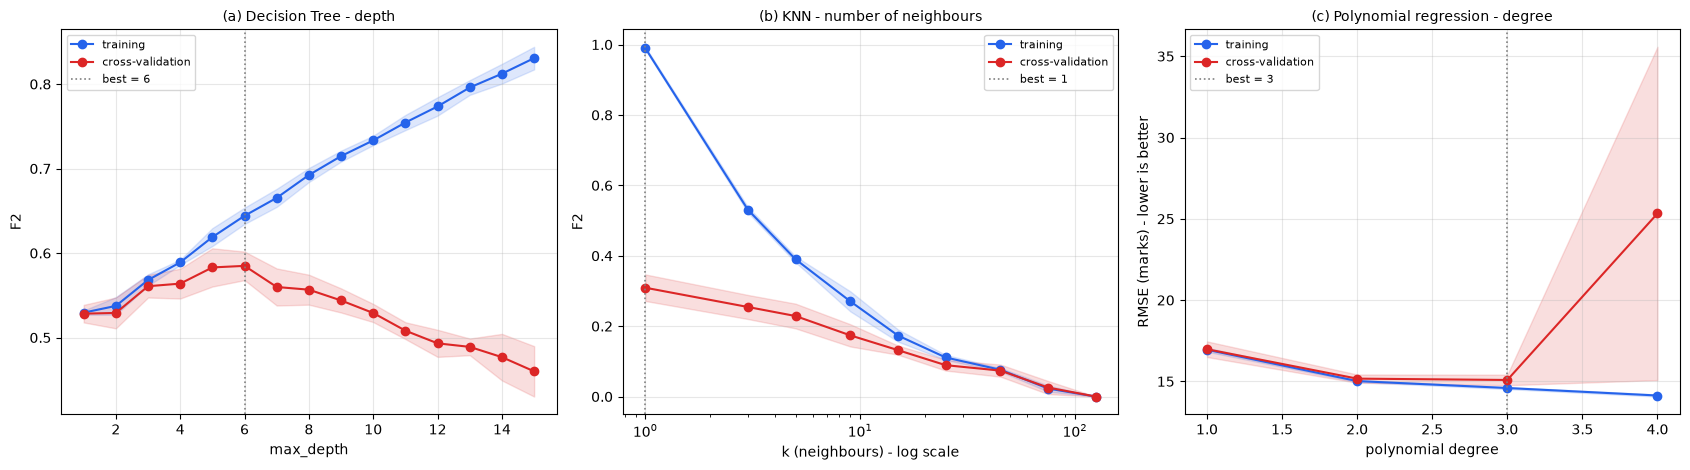

        model parameter  value  train     cv     gap
Decision Tree max_depth      1  0.530  0.528   0.001
Decision Tree max_depth      2  0.537  0.529   0.008
Decision Tree max_depth      3  0.568  0.561   0.007
Decision Tree max_depth      4  0.589  0.564   0.025
Decision Tree max_depth      5  0.619  0.583   0.036
Decision Tree max_depth      6  0.644  0.585   0.059
Decision Tree max_depth      7  0.665  0.560   0.106
Decision Tree max_depth      8  0.692  0.557   0.136
Decision Tree max_depth      9  0.715  0.544   0.171
Decision Tree max_depth     10  0.733  0.529   0.204
Decision Tree max_depth     11  0.755  0.508   0.246
Decision Tree max_depth     12  0.774  0.493   0.280
Decision Tree max_depth     13  0.796  0.489   0.307
Decision Tree max_depth     14  0.812  0.477   0.335
Decision Tree max_depth     15  0.831  0.460   0.371
          KNN         k      1  0.990  0.309   0.680
          KNN         k      3  0.531  0.254   0.277
          KNN         k      5  0.390  0.229  

In [39]:
from sklearn.model_selection import validation_curve, learning_curve


def plot_curve(ax, x, train_scores, val_scores, xlabel, ylabel, title,
               higher_is_better=True, mark_best=True):
    tr_m, va_m = train_scores.mean(axis=1), val_scores.mean(axis=1)
    tr_s, va_s = train_scores.std(axis=1), val_scores.std(axis=1)
    ax.plot(x, tr_m, "o-", color="#2563eb", label="training")
    ax.fill_between(x, tr_m - tr_s, tr_m + tr_s, color="#2563eb", alpha=0.15)
    ax.plot(x, va_m, "o-", color="#dc2626", label="cross-validation")
    ax.fill_between(x, va_m - va_s, va_m + va_s, color="#dc2626", alpha=0.15)
    best = x[int(np.argmax(va_m) if higher_is_better else np.argmin(va_m))]
    if mark_best:
        ax.axvline(best, color="gray", ls=":", lw=1.2, label=f"best = {best}")
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8)
    return best, tr_m, va_m


fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
diagnostics = []

depths = np.arange(1, 16)
tr, va = validation_curve(
    make(tree_preprocessor, DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE)),
    X_train, y_train, param_name="model__max_depth", param_range=depths,
    cv=cv_clf, scoring=f2_scorer, n_jobs=-1)
best_depth, tr_m, va_m = plot_curve(axes[0], depths, tr, va, "max_depth", "F2",
                                    "(a) Decision Tree - depth")
diagnostics += [("Decision Tree", "max_depth", d, t, v) for d, t, v in zip(depths, tr_m, va_m)]

ks = np.array([1, 3, 5, 9, 15, 25, 45, 75, 125])
tr, va = validation_curve(
    make(preprocessor, KNeighborsClassifier()), X_train, y_train,
    param_name="model__n_neighbors", param_range=ks, cv=cv_clf, scoring=f2_scorer, n_jobs=-1)
best_k, tr_m, va_m = plot_curve(axes[1], ks, tr, va, "k (neighbours) - log scale", "F2",
                                "(b) KNN - number of neighbours")
axes[1].set_xscale("log")
diagnostics += [("KNN", "k", k, t, v) for k, t, v in zip(ks, tr_m, va_m)]

degrees = np.arange(1, 5)
tr, va = validation_curve(
    regressors["Polynomial Regression (deg 2)"], X_train, y_train_reg,
    param_name="poly__degree", param_range=degrees, cv=cv_reg,
    scoring="neg_root_mean_squared_error", n_jobs=-1)
best_degree, tr_m, va_m = plot_curve(axes[2], degrees, -tr, -va, "polynomial degree",
                                     "RMSE (marks) - lower is better",
                                     "(c) Polynomial regression - degree",
                                     higher_is_better=False)
if (-va).mean(axis=1).max() > 3 * (-va).mean(axis=1).min():
    axes[2].set_yscale("log")
diagnostics += [("Polynomial", "degree", d, t, v) for d, t, v in zip(degrees, tr_m, va_m)]

plt.tight_layout(); show("14_bias_variance_curves")

diag = pd.DataFrame(diagnostics, columns=["model", "parameter", "value", "train", "cv"])
diag["gap"] = diag["train"] - diag["cv"]
print(diag.round(3).to_string(index=False))
print(f"\nBest Decision Tree depth: {best_depth} | best KNN k: {best_k} | "
      f"best polynomial degree: {best_degree}")

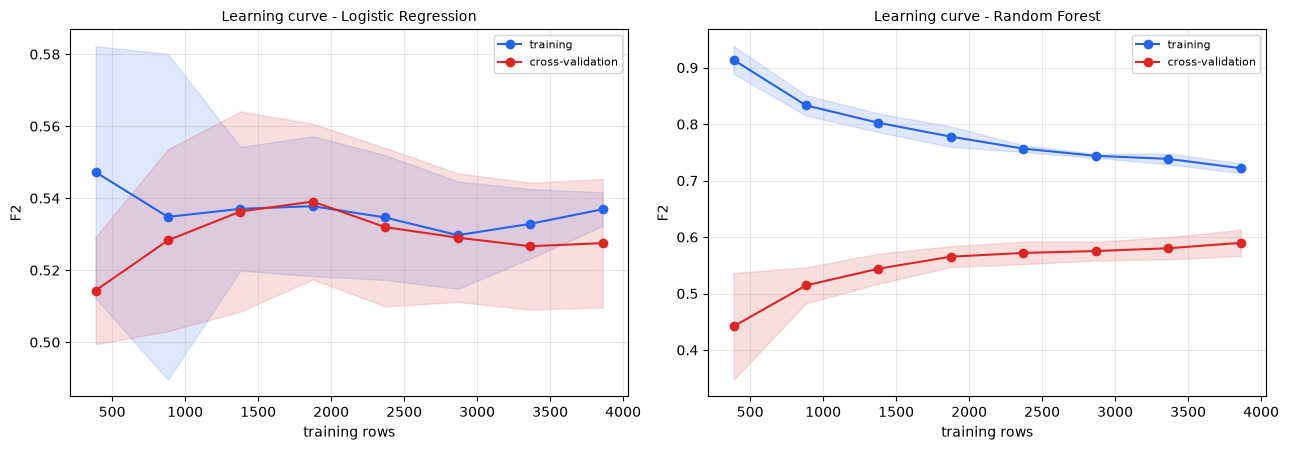

Logistic Regression
 rows  train_F2  cv_F2
  386     0.547  0.514
  882     0.535  0.528
 1378     0.537  0.536
 1874     0.538  0.539
 2371     0.535  0.532
 2867     0.530  0.529
 3363     0.533  0.527
 3860     0.537  0.528

Random Forest
 rows  train_F2  cv_F2
  386     0.914  0.442
  882     0.833  0.514
 1378     0.802  0.544
 1874     0.778  0.565
 2371     0.757  0.572
 2867     0.744  0.575
 3363     0.739  0.580
 3860     0.722  0.590



In [40]:
sizes = np.linspace(0.1, 1.0, 8)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
learning = {}
for ax, name in zip(axes, ["Logistic Regression", "Random Forest"]):
    n_rows, tr, va = learning_curve(
        classifiers[name], X_train, y_train, train_sizes=sizes, cv=cv_clf,
        scoring=f2_scorer, n_jobs=-1, shuffle=True, random_state=RANDOM_STATE)
    _, tr_m, va_m = plot_curve(ax, n_rows, tr, va, "training rows", "F2",
                               f"Learning curve - {name}", mark_best=False)
    learning[name] = pd.DataFrame({"rows": n_rows, "train_F2": tr_m, "cv_F2": va_m})
plt.tight_layout(); show("15_learning_curves")

for name, table in learning.items():
    print(name); print(table.round(3).to_string(index=False)); print()

**All three experiments show the textbook U-shape.**

- **(a) Decision Tree depth.** From depth 1 to 6, training and CV F2 rise together — the model is learning real structure (reducing **bias**). Beyond depth 6 the training score keeps climbing (0.64 → 0.83) while CV *falls* (0.585 → 0.46): the extra depth is memorising individual students (**variance**). **Best depth = 6.**
- **(b) KNN `k`.** At `k = 1` the training F2 is 0.99 but CV only 0.31 — pure memorisation. As `k` grows the gap closes, but *both* scores collapse towards 0: a large neighbourhood is dominated by the 89% majority class, so the minority is never voted in. For imbalanced data KNN has no good setting — this is a structural weakness of the algorithm here, not a tuning problem.
- **(c) Polynomial degree.** Degree 1 → 2 → 3 lowers the CV error (17.0 → 15.2 → 15.1 marks). At **degree 4** the training error keeps falling (14.1) but the CV error explodes to **25.3**, with huge fold-to-fold variation (the shaded band): ~3,000 polynomial terms on ~3,900 rows is enough to fit noise. Degree 2 is used — degree 3 is only 0.08 marks better for many more terms.

**Learning curves — would more data help?**

- **Logistic Regression** is flat: training and CV converge at ~0.53 almost immediately. More data will **not** help a model this simple — it is bias-limited.
- **Random Forest** still has a gap that is *closing*: CV F2 climbs steadily from 0.44 (386 rows) to 0.59 (3,860 rows) and has not levelled off. This model **is still data-hungry** — direct evidence that enlarging the dataset (the reason OULAD was added) improves the model, and that more data would improve it further.

---
# 19. Hyperparameter tuning and final model selection

Section 18 varied one setting at a time. **`GridSearchCV`** searches every
combination of several settings, scoring each with the same 5-fold
cross-validation and the same F2 metric, and keeps the best. Only the training set
is used.

Three classifiers are tuned — the linear model, the single tree and the ensemble —
plus the Random Forest regressor:

| Model | Settings searched |
|---|---|
| Logistic Regression | `C` — inverse regularisation strength (small `C` = simpler model) |
| Decision Tree | `max_depth`, `min_samples_leaf` |
| Random Forest | `max_depth`, `min_samples_leaf` |
| Random Forest Regressor | `max_depth`, `min_samples_leaf` (scored on RMSE) |

### The selection rule, stated before looking at the test set

- **Classifier:** the highest **cross-validated F2** across all twelve candidates (six defaults + three tuned).
- **Regressor:** the lowest **cross-validated RMSE**.

Only *after* the choice is made is the chosen model scored on the untouched test
set — once. Choosing by test-set score would quietly turn the test set into a
second validation set and make the final number optimistic.

In [41]:
from sklearn.model_selection import GridSearchCV

search_spaces = {
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10, 100]},
    "Decision Tree": {"model__max_depth": [3, 4, 5, 6, 8, 10],
                      "model__min_samples_leaf": [1, 10, 30]},
    "Random Forest": {"model__max_depth": [4, 6, 8, 12, None],
                      "model__min_samples_leaf": [1, 5, 10]},
}

tuned_clf, tuning_rows = {}, []
for name, grid in search_spaces.items():
    gs = GridSearchCV(classifiers[name], grid, cv=cv_clf, scoring=f2_scorer, n_jobs=-1)
    gs.fit(X_train, y_train)
    tuned_clf[f"{name} (tuned)"] = gs.best_estimator_
    tuning_rows.append({
        "Model": name,
        "Default CV F2": cv_clf_table.loc[name, "F2"],
        "Tuned CV F2": gs.best_score_,
        "Combinations tried": len(gs.cv_results_["params"]),
        "Best settings": {k.replace("model__", ""): v for k, v in gs.best_params_.items()},
    })

tuning_table = pd.DataFrame(tuning_rows).set_index("Model")
print(tuning_table.round(3).to_string())

                     Default CV F2  Tuned CV F2  Combinations tried                             Best settings
Model                                                                                                        
Logistic Regression          0.528        0.535                   5                               {'C': 0.01}
Decision Tree                0.583        0.587                  18  {'max_depth': 6, 'min_samples_leaf': 10}
Random Forest                0.592        0.608                  15   {'max_depth': 6, 'min_samples_leaf': 1}


In [42]:
gs_reg = GridSearchCV(
    regressors["Random Forest Regressor"],
    {"model__max_depth": [6, 10, 14, None], "model__min_samples_leaf": [1, 5, 10]},
    cv=cv_reg, scoring="neg_root_mean_squared_error", n_jobs=-1,
).fit(X_train, y_train_reg)
tuned_reg = {"Random Forest Regressor (tuned)": gs_reg.best_estimator_}

print("Random Forest Regressor")
print(f"  default CV RMSE: {cv_reg_table.loc['Random Forest Regressor', 'RMSE']:.3f}")
print(f"  tuned   CV RMSE: {-gs_reg.best_score_:.3f}")
print(f"  best settings  : { {k.replace('model__', ''): v for k, v in gs_reg.best_params_.items()} }")

Random Forest Regressor
  default CV RMSE: 14.333
  tuned   CV RMSE: 14.230
  best settings  : {'max_depth': 10, 'min_samples_leaf': 5}


In [43]:
# --- Final selection: by cross-validation only -------------------------------
clf_candidates = {name: cv_clf_table.loc[name, "F2"] for name in classifiers}
clf_candidates.update({f"{name} (tuned)": tuning_table.loc[name, "Tuned CV F2"]
                       for name in tuning_table.index})
all_classifiers = {**classifiers, **tuned_clf}

reg_candidates = {name: cv_reg_table.loc[name, "RMSE"] for name in regressors}
reg_candidates["Random Forest Regressor (tuned)"] = -gs_reg.best_score_
all_regressors = {**regressors, **tuned_reg}

final_clf_name = max(clf_candidates, key=clf_candidates.get)
final_reg_name = min(reg_candidates, key=reg_candidates.get)
final_clf = all_classifiers[final_clf_name]   # every candidate is fitted on X_train
final_reg = all_regressors[final_reg_name]

print("Cross-validated F2 of every classification candidate:")
print(pd.Series(clf_candidates).sort_values(ascending=False).round(3).to_string())
print("\nCross-validated RMSE of every regression candidate:")
print(pd.Series(reg_candidates).sort_values().round(3).to_string())

# --- The one and only test-set evaluation of the chosen models ---------------
final_pred = final_clf.predict(X_test)
final_proba = final_clf.predict_proba(X_test)[:, 1]
final_clf_test = clf_metrics(y_test, final_pred, final_proba)
final_reg_test = reg_metrics(y_test_reg, final_reg.predict(X_test))

print(f"\nSELECTED CLASSIFIER: {final_clf_name}")
print(pd.Series(final_clf_test).round(3).to_string())
print(f"\nSELECTED REGRESSOR : {final_reg_name}")
print(pd.Series(final_reg_test).round(3).to_string())

Cross-validated F2 of every classification candidate:
Random Forest (tuned)          0.608
Random Forest                  0.592
SVM (RBF kernel)               0.589
Decision Tree (tuned)          0.587
Decision Tree                  0.583
Logistic Regression (tuned)    0.535
Logistic Regression            0.528
Naive Bayes                    0.385
K-Nearest Neighbours           0.136

Cross-validated RMSE of every regression candidate:
Random Forest Regressor (tuned)    14.230
Random Forest Regressor            14.333
Polynomial Regression (deg 2)      15.169
Multiple Linear Regression         16.978

SELECTED CLASSIFIER: Random Forest (tuned)
Accuracy      0.753
Precision     0.291
Recall        0.865
F1            0.436
F2            0.620
ROC-AUC       0.876
Missed       18.000

SELECTED REGRESSOR : Random Forest Regressor (tuned)
MAE      10.968
MSE     206.662
RMSE     14.376
R2        0.529


**Tuning results.**

| Model | CV F2 before | CV F2 after | Chosen settings |
|---|---|---|---|
| Logistic Regression | 0.528 | 0.535 | `C = 0.01` (strong regularisation) |
| Decision Tree | 0.583 | 0.587 | `max_depth = 6`, `min_samples_leaf = 10` |
| **Random Forest** | 0.592 | **0.608** | `max_depth = 6`, `min_samples_leaf = 1` |
| RF Regressor (RMSE) | 14.33 | **14.23** | `max_depth = 10`, `min_samples_leaf = 5` |

Tuning chose **shallower** trees than the defaults (depth 6 instead of 8 for the forest) — the
grid search independently found the same lesson as section 18: limit complexity to cut variance.

### Selected models

**Classifier: Random Forest (tuned).** Highest cross-validated F2 of all nine candidates. On the
untouched test set: **recall 0.865** (caught 115 of 133 at-risk students), F2 0.620,
ROC-AUC 0.876.

**Regressor: Random Forest Regressor (tuned).** Lowest cross-validated RMSE. On the test set:
**MAE 10.97 marks, R² 0.529.**

**Why Random Forest suits this problem**

1. **Non-linear and interaction effects** — a falling trend *combined with* low engagement is riskier than either alone; trees capture this without the effects being specified by hand.
2. **Handles mixed inputs** — numeric marks and one-hot categories, with no scaling required.
3. **Robust to overfitting through averaging** — 300 trees, each on a bootstrap sample with random feature subsets; individual trees overfit, their average does not overfit as much.
4. **`class_weight="balanced"`** directly addresses the 11% minority class.
5. **Interpretable enough** — feature importances (section 21) show what drives a prediction.

---
# 20. Unsupervised learning — do students form natural groups?

Everything so far was **supervised**: the models were shown the answer
(`at_risk`, `final_marks`) and learned to reproduce it. Clustering asks a
different question, with **no labels at all**: if we only look at a student's
attendance, internal and midterm marks, do students fall into natural groups?

If the groups turn out to line up with academic risk, that is an independent
confirmation of the supervised result — found without ever telling the
algorithm who failed. It also has a practical use: a teacher can be handed a
small number of **student profiles** to plan interventions around, rather than a
ranked list.

Three algorithms, each with a different idea of what a "group" is:

| Algorithm | A cluster is... | Needs in advance | Notes |
|---|---|---|---|
| **K-Means** | the students nearest to one of *k* centres | the number of clusters *k* | fast; prefers round, similar-sized clusters |
| **Hierarchical (agglomerative, Ward)** | built bottom-up by repeatedly merging the two closest groups | nothing — *k* is chosen by cutting the dendrogram | shows the whole merge history |
| **DBSCAN** | a dense region of points | a radius `eps` and `min_samples` | finds clusters of any shape and labels sparse points as **noise** |

**Silhouette score** measures cluster quality without labels: for each student,
`(b - a) / max(a, b)`, where *a* is the mean distance to its own cluster and *b*
to the nearest other cluster. It ranges from -1 (wrong cluster) through 0
(overlapping) to +1 (tight, well separated).

The three input features are **standardised** first — clustering is
distance-based, so unscaled marks would dominate.

Clustering 6033 students on ['attendance_percentage', 'internal_marks', 'midterm_marks'] (standardised)



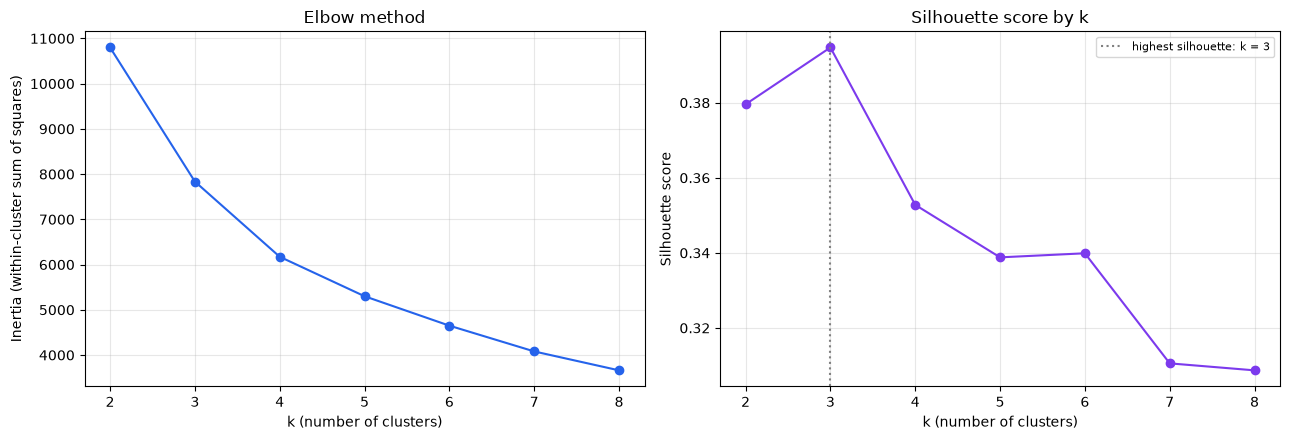

 k  inertia  silhouette
 2  10800.0       0.380
 3   7835.0       0.395
 4   6172.0       0.353
 5   5300.0       0.339
 6   4649.0       0.340
 7   4080.0       0.311
 8   3662.0       0.309


In [44]:
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors

CLUSTER_FEATURES = ["attendance_percentage", "internal_marks", "midterm_marks"]
cluster_frame = featured[CLUSTER_FEATURES + ["at_risk", "final_marks", "source"]].dropna().copy()
Xc = StandardScaler().fit_transform(cluster_frame[CLUSTER_FEATURES])
print(f"Clustering {len(Xc)} students on {CLUSTER_FEATURES} (standardised)\n")

k_values = list(range(2, 9))
inertias, silhouettes = [], []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xc)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(Xc, km.labels_))

best_k_sil = k_values[int(np.argmax(silhouettes))]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(k_values, inertias, "o-", color="#2563eb")
axes[0].set_xlabel("k (number of clusters)"); axes[0].set_ylabel("Inertia (within-cluster sum of squares)")
axes[0].set_title("Elbow method")
axes[1].plot(k_values, silhouettes, "o-", color="#7c3aed")
axes[1].axvline(best_k_sil, color="gray", ls=":", label=f"highest silhouette: k = {best_k_sil}")
axes[1].set_xlabel("k (number of clusters)"); axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Silhouette score by k"); axes[1].legend(fontsize=8)
plt.tight_layout(); show("16_kmeans_elbow_silhouette")

print(pd.DataFrame({"k": k_values, "inertia": np.round(inertias, 0),
                    "silhouette": np.round(silhouettes, 3)}).to_string(index=False))

K-Means cluster profiles (sorted by at-risk rate):

        students  attendance  internal  midterm  final  at_risk_pct
kmeans                                                             
0           3177        89.3      83.7     76.6   72.8          3.3
1           1271        59.0      70.3     48.5   56.6         18.3
2           1585        87.6      44.6     38.8   52.6         20.8

Share of each source inside each cluster:
source   ERP  OULAD   UCI
kmeans                   
0       0.01   0.87  0.12
1       0.00   0.97  0.03
2       0.00   0.60  0.40


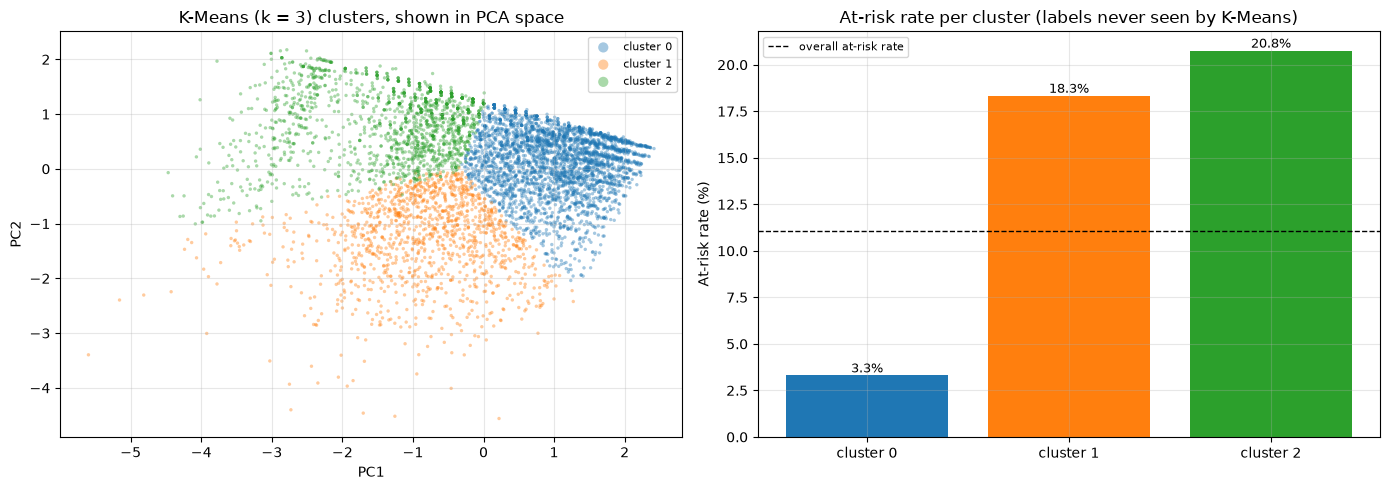

In [45]:
# Fit K-Means with the chosen k, then profile each cluster. The labels at_risk and
# final_marks were NOT used to form the clusters - they are only looked at now.
N_CLUSTERS = best_k_sil
kmeans = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=RANDOM_STATE).fit(Xc)
cluster_frame["kmeans"] = kmeans.labels_

profile = (cluster_frame.groupby("kmeans")
           .agg(students=("at_risk", "size"),
                attendance=("attendance_percentage", "mean"),
                internal=("internal_marks", "mean"),
                midterm=("midterm_marks", "mean"),
                final=("final_marks", "mean"),
                at_risk_pct=("at_risk", "mean"))
           .sort_values("at_risk_pct"))
profile["at_risk_pct"] *= 100
print("K-Means cluster profiles (sorted by at-risk rate):\n")
print(profile.round(1).to_string())
print("\nShare of each source inside each cluster:")
print(pd.crosstab(cluster_frame["kmeans"], cluster_frame["source"], normalize="index")
      .loc[profile.index].round(2).to_string())

coords_c = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(Xc)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
palette = plt.cm.tab10.colors
for c in profile.index:
    m = cluster_frame["kmeans"].values == c
    axes[0].scatter(coords_c[m, 0], coords_c[m, 1], s=6, alpha=0.4, color=palette[c % 10],
                    label=f"cluster {c}", edgecolors="none")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")
axes[0].set_title(f"K-Means (k = {N_CLUSTERS}) clusters, shown in PCA space")
axes[0].legend(fontsize=8, markerscale=3)

bars = axes[1].bar([f"cluster {c}" for c in profile.index], profile["at_risk_pct"],
                   color=[palette[c % 10] for c in profile.index])
for bar, v in zip(bars, profile["at_risk_pct"]):
    axes[1].text(bar.get_x() + bar.get_width() / 2, v, f"{v:.1f}%", ha="center", va="bottom", fontsize=9)
axes[1].axhline(100 * cluster_frame["at_risk"].mean(), color="black", ls="--", lw=1,
                label="overall at-risk rate")
axes[1].set_ylabel("At-risk rate (%)"); axes[1].legend(fontsize=8)
axes[1].set_title("At-risk rate per cluster (labels never seen by K-Means)")
plt.tight_layout(); show("17_kmeans_clusters")

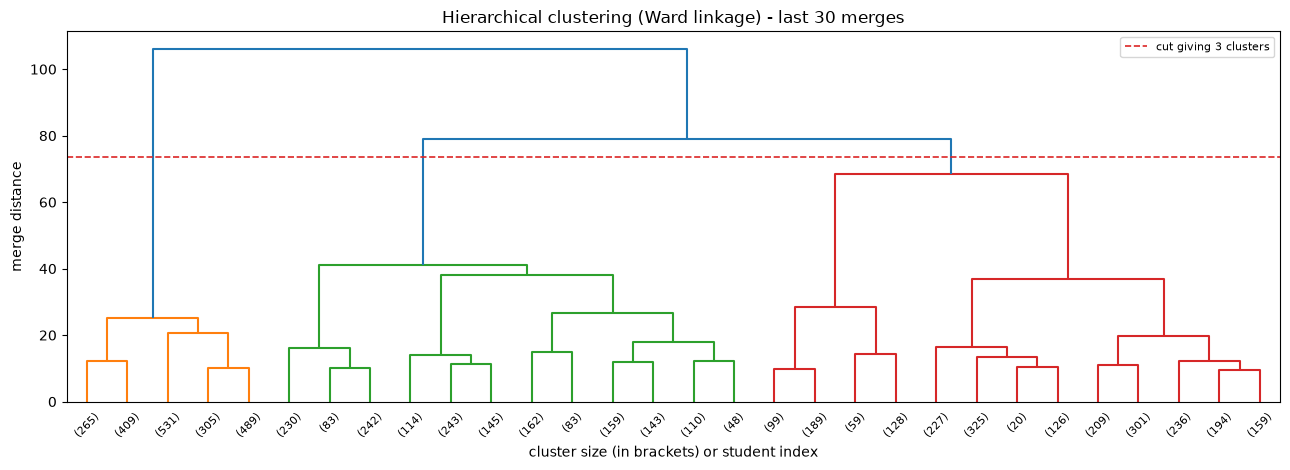

              students  final  at_risk_pct
hierarchical                              
1                 1999   77.8          1.4
3                 2272   57.0         15.1
2                 1762   57.8         16.9

Silhouette (hierarchical, 3 clusters): 0.293
Agreement with K-Means (adjusted Rand index, 1 = identical): 0.413


In [46]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

Z = linkage(Xc, method="ward")
CUT = (Z[-N_CLUSTERS, 2] + Z[-N_CLUSTERS + 1, 2]) / 2   # between the merges that give N and N-1 clusters
hier_labels = fcluster(Z, t=N_CLUSTERS, criterion="maxclust")
hier_sil = silhouette_score(Xc, hier_labels)
agreement = adjusted_rand_score(kmeans.labels_, hier_labels)

fig, ax = plt.subplots(figsize=(13, 4.8))
dendrogram(Z, truncate_mode="lastp", p=30, ax=ax, color_threshold=CUT,
           show_leaf_counts=True, leaf_font_size=8)
ax.axhline(CUT, color="#dc2626", ls="--", lw=1.2,
           label=f"cut giving {N_CLUSTERS} clusters")
ax.set_title("Hierarchical clustering (Ward linkage) - last 30 merges")
ax.set_xlabel("cluster size (in brackets) or student index"); ax.set_ylabel("merge distance")
ax.legend(fontsize=8); ax.grid(False)
plt.tight_layout(); show("18_dendrogram")

cluster_frame["hierarchical"] = hier_labels
hier_profile = cluster_frame.groupby("hierarchical").agg(
    students=("at_risk", "size"), final=("final_marks", "mean"),
    at_risk_pct=("at_risk", "mean")).sort_values("at_risk_pct")
hier_profile["at_risk_pct"] *= 100
print(hier_profile.round(1).to_string())
print(f"\nSilhouette (hierarchical, {N_CLUSTERS} clusters): {hier_sil:.3f}")
print(f"Agreement with K-Means (adjusted Rand index, 1 = identical): {agreement:.3f}")

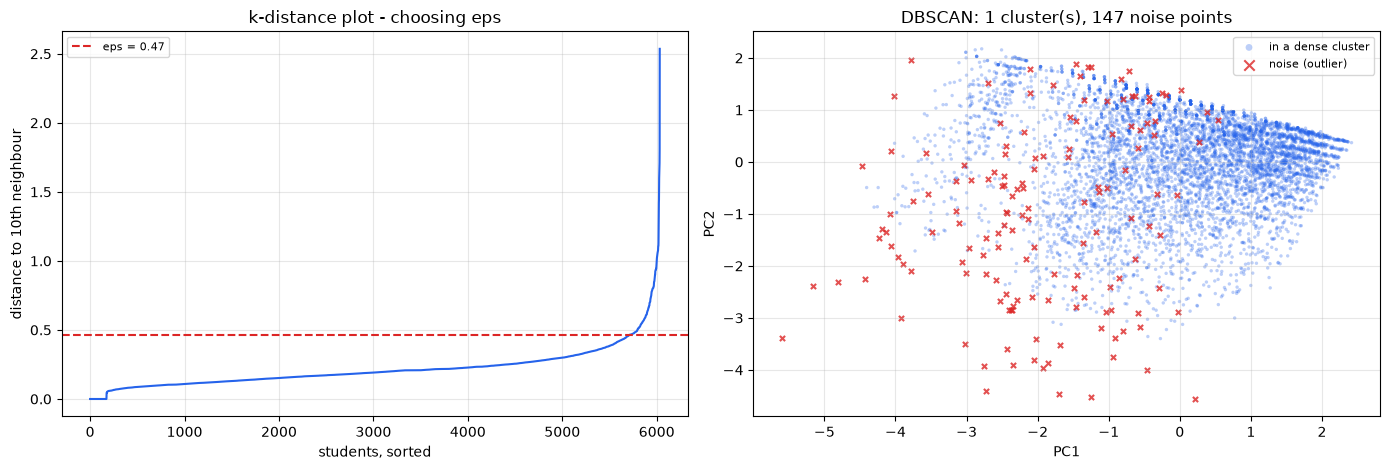

eps = 0.467, min_samples = 10
Clusters found: 1 | noise points: 147 (2.4%)
At-risk rate - noise points : 23.1%
At-risk rate - everyone else: 10.8%


In [47]:
MIN_SAMPLES = 10
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Xc)
k_dist = np.sort(nn.kneighbors(Xc)[0][:, -1])
EPS = float(np.quantile(k_dist, 0.95))   # the "knee": 95% of students lie within this radius

db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit(Xc)
db_labels = db.labels_
noise = db_labels == -1
n_db_clusters = len(set(db_labels)) - (1 if noise.any() else 0)
db_sil = silhouette_score(Xc[~noise], db_labels[~noise]) if n_db_clusters >= 2 else np.nan
cluster_frame["dbscan_noise"] = noise

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].plot(k_dist, color="#2563eb")
axes[0].axhline(EPS, color="#dc2626", ls="--", label=f"eps = {EPS:.2f}")
axes[0].set_xlabel("students, sorted"); axes[0].set_ylabel(f"distance to {MIN_SAMPLES}th neighbour")
axes[0].set_title("k-distance plot - choosing eps"); axes[0].legend(fontsize=8)

axes[1].scatter(coords_c[~noise, 0], coords_c[~noise, 1], s=6, alpha=0.3, color="#2563eb",
                label="in a dense cluster", edgecolors="none")
axes[1].scatter(coords_c[noise, 0], coords_c[noise, 1], s=14, alpha=0.8, color="#dc2626",
                marker="x", label="noise (outlier)")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
axes[1].set_title(f"DBSCAN: {n_db_clusters} cluster(s), {noise.sum()} noise points")
axes[1].legend(fontsize=8, markerscale=2)
plt.tight_layout(); show("19_dbscan")

print(f"eps = {EPS:.3f}, min_samples = {MIN_SAMPLES}")
print(f"Clusters found: {n_db_clusters} | noise points: {noise.sum()} ({100 * noise.mean():.1f}%)")
print(f"At-risk rate - noise points : {100 * cluster_frame.loc[noise, 'at_risk'].mean():.1f}%")
print(f"At-risk rate - everyone else: {100 * cluster_frame.loc[~noise, 'at_risk'].mean():.1f}%")

In [48]:
cluster_comparison = pd.DataFrame([
    {"Method": "K-Means", "Clusters": N_CLUSTERS,
     "Silhouette": silhouette_score(Xc, kmeans.labels_), "Noise %": 0.0},
    {"Method": "Hierarchical (Ward)", "Clusters": N_CLUSTERS,
     "Silhouette": hier_sil, "Noise %": 0.0},
    {"Method": "DBSCAN", "Clusters": n_db_clusters,
     "Silhouette": db_sil, "Noise %": 100 * noise.mean()},
]).set_index("Method")
print(cluster_comparison.round(3).to_string())

                     Clusters  Silhouette  Noise %
Method                                            
K-Means                     3       0.395    0.000
Hierarchical (Ward)         3       0.293    0.000
DBSCAN                      1         NaN    2.437


**What the clustering found — without ever seeing a label.**

K-Means with **k = 3** (highest silhouette, 0.395) splits students into three recognisable profiles:

| Cluster | Students | Attendance | Internal | Midterm | Avg final | **At risk** | Profile |
|---|---|---|---|---|---|---|---|
| 0 | 3,177 | 89% | 84 | 77 | 72.8 | **3.3%** | engaged, strong coursework |
| 1 | 1,271 | **59%** | 70 | 49 | 56.6 | **18.3%** | **disengaging** — attendance and midterm both falling |
| 2 | 1,585 | 88% | **45** | **39** | 52.6 | **20.8%** | **attending but struggling** with the material |

- The algorithm was never told who failed, yet it produced a low-risk group (3.3%) and two high-risk groups at ~6× that rate. Unsupervised learning **independently confirms** that these three signals carry risk information.
- More usefully, it separates **two different kinds of at-risk student** who need **different interventions**: cluster 1 needs re-engagement (attendance), cluster 2 needs academic support (tutoring). A supervised "at risk: yes/no" label cannot make that distinction.

**Hierarchical clustering** (Ward, cut at 3 clusters) finds the same overall structure — one
low-risk group at 1.4% and two higher-risk groups at 15-17% — with a lower silhouette (0.293)
and moderate agreement with K-Means (adjusted Rand index 0.41). Two different algorithms
arriving at a similar picture is evidence the structure is real.

**DBSCAN** finds **one** dense cluster plus 147 noise points (2.4%) — these students are not
separated by gaps of low density; they form one continuous population. DBSCAN's value here is
**outlier detection**: the noise points have an at-risk rate of **23.1%**, more than double the
10.8% of everyone else. Students with unusual combinations of attendance and marks deserve a
closer look.

| Method | Clusters | Silhouette |
|---|---|---|
| **K-Means** | 3 | **0.395** |
| Hierarchical (Ward) | 3 | 0.293 |
| DBSCAN | 1 + noise | not defined (one cluster) |

---
# 21. Feature importance and interpretation

Which features drive the predictions?

**A caution on wording.** Feature importance shows *association*, not causation.
"Attendance is strongly associated with the prediction" is supportable. "Attending
class causes higher marks" is not — attendance may be standing in for motivation,
health, or circumstances the data never records. The wording below stays on the
defensible side of that line.

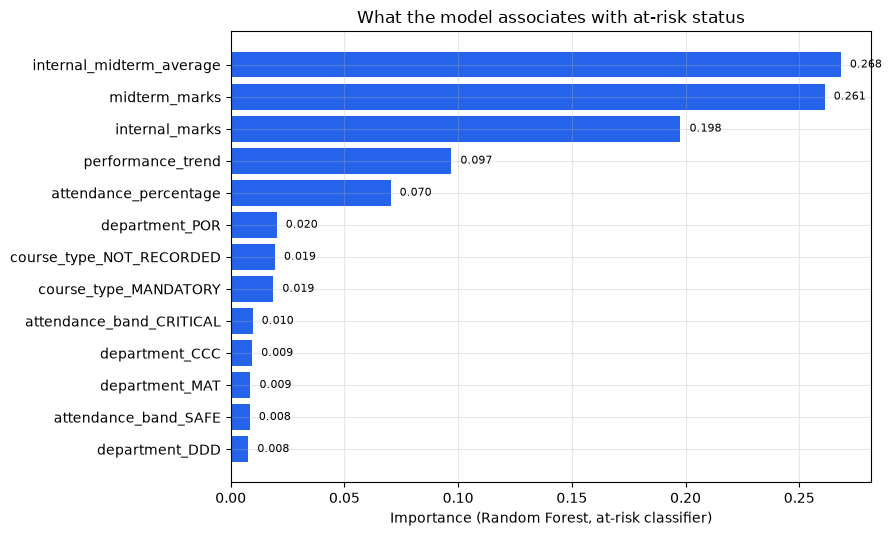

internal_midterm_average    0.2683
midterm_marks               0.2612
internal_marks              0.1977
performance_trend           0.0970
attendance_percentage       0.0703
department_POR              0.0202
course_type_NOT_RECORDED    0.0194
course_type_MANDATORY       0.0187
attendance_band_CRITICAL    0.0096
department_CCC              0.0094
department_MAT              0.0086
attendance_band_SAFE        0.0084
department_DDD              0.0077


In [49]:
rf_clf = classifiers["Random Forest"]
feature_names = rf_clf.named_steps["prep"].get_feature_names_out()
importances = rf_clf.named_steps["model"].feature_importances_

imp = (pd.Series(importances, index=[n.split("__", 1)[-1] for n in feature_names])
       .sort_values(ascending=True))
imp = imp[imp > 0.005]

fig, ax = plt.subplots(figsize=(9, max(4, 0.42 * len(imp))))
ax.barh(imp.index, imp.values, color="#2563eb")
ax.set_xlabel("Importance (Random Forest, at-risk classifier)")
ax.set_title("What the model associates with at-risk status")
for i, v in enumerate(imp.values):
    ax.text(v + 0.004, i, f"{v:.3f}", va="center", fontsize=8)
plt.tight_layout(); show("20_feature_importance")

print(imp.sort_values(ascending=False).round(4).to_string())

**Reading the importances.**

- The three mark features — `internal_midterm_average`, `midterm_marks`, `internal_marks` — carry about 73% of the importance between them.
- **`performance_trend` (0.097)** ranks fourth, ahead of attendance — the *direction* of a student's marks matters, which is exactly why it was engineered (section 8).
- **`attendance_percentage` (0.070)** contributes meaningfully, unlike in CE-1 where it barely registered — the OULAD engagement data gives it signal.
- The department and course-type columns carry small weights: they mostly let the model adjust for each source's different grading behaviour.

---
# 22. Fairness audit and ethical considerations

A model can be accurate *on average* and still fail one group of students
systematically. The CE-1 notebook listed this as an unaudited risk; here it is
measured.

The selected classifier and regressor are evaluated on the **test set, broken
down by data source and by department**:

- **Recall per group** — are at-risk students in one group missed more often?
- **False-positive rate per group** — are students in one group flagged unnecessarily more often?
- **MAE per group** — are one group's marks predicted less accurately?

Groups with very few at-risk students give unstable rates, so the counts are
shown alongside.

By data source:

        students  at_risk  recall  false_positive_rate  MAE_marks
source                                                           
ERP          6.0      0.0     NaN                0.167      3.257
OULAD     1010.0    111.0   0.847                0.296     12.107
UCI        191.0     22.0   0.955                0.077      5.187

By department:

            students  at_risk  recall  false_positive_rate  MAE_marks
department                                                           
CCC            368.0     43.0   0.837                0.320     12.888
CSE              6.0      0.0     NaN                0.167      3.257
DDD            642.0     68.0   0.853                0.282     11.660
MAT             69.0     16.0   1.000                0.170      6.063
POR            122.0      6.0   0.833                0.034      4.691


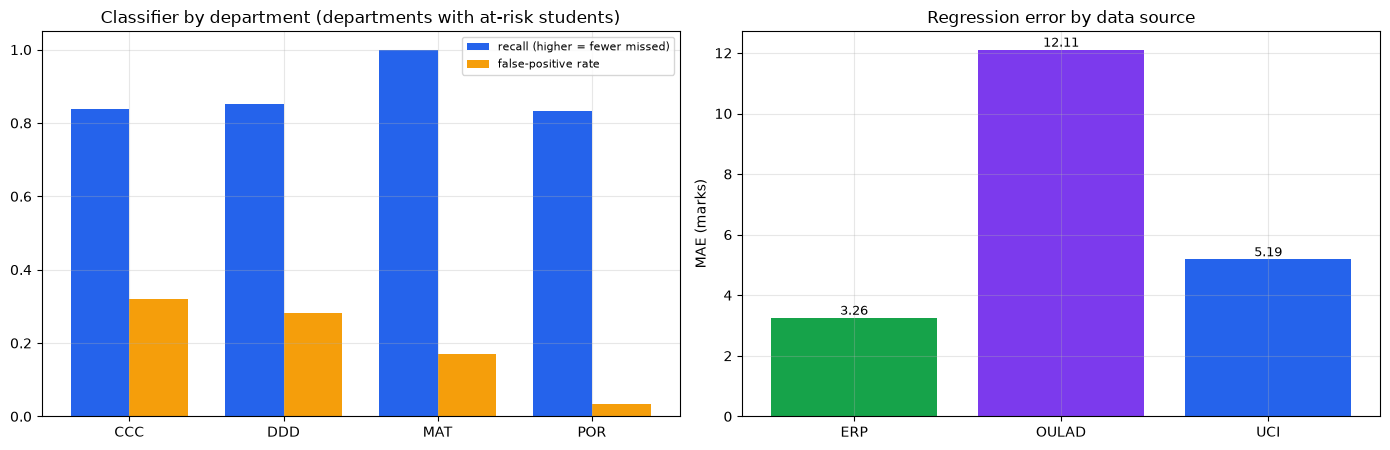

In [50]:
audit = featured.loc[X_test.index, ["source", "department"]].copy()
audit["y"] = y_test.values
audit["pred"] = final_clf.predict(X_test)
audit["y_reg"] = y_test_reg.values
audit["pred_reg"] = final_reg.predict(X_test)


def group_report(g):
    pos, neg = g["y"] == 1, g["y"] == 0
    return pd.Series({
        "students": len(g),
        "at_risk": int(pos.sum()),
        "recall": (g.loc[pos, "pred"] == 1).mean() if pos.any() else np.nan,
        "false_positive_rate": (g.loc[neg, "pred"] == 1).mean() if neg.any() else np.nan,
        "MAE_marks": mean_absolute_error(g["y_reg"], g["pred_reg"]),
    })


by_source = audit.groupby("source")[["y", "pred", "y_reg", "pred_reg"]].apply(group_report)
by_dept = audit.groupby("department")[["y", "pred", "y_reg", "pred_reg"]].apply(group_report)
print("By data source:\n"); print(by_source.round(3).to_string())
print("\nBy department:\n"); print(by_dept.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
d = by_dept.dropna(subset=["recall"])
xs = np.arange(len(d)); w = 0.38
axes[0].bar(xs - w/2, d["recall"], w, label="recall (higher = fewer missed)", color="#2563eb")
axes[0].bar(xs + w/2, d["false_positive_rate"], w, label="false-positive rate", color="#f59e0b")
axes[0].set_xticks(xs); axes[0].set_xticklabels(d.index); axes[0].set_ylim(0, 1.05)
axes[0].set_title("Classifier by department (departments with at-risk students)")
axes[0].legend(fontsize=8)

s = by_source
axes[1].bar(s.index, s["MAE_marks"], color=[src_colors.get(i, "#64748b") for i in s.index])
for i, v in enumerate(s["MAE_marks"]):
    axes[1].text(i, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9)
axes[1].set_ylabel("MAE (marks)"); axes[1].set_title("Regression error by data source")
plt.tight_layout(); show("21_fairness_by_group")

**What the audit shows.**

| Group | At-risk in test | Recall | False-positive rate | MAE (marks) |
|---|---|---|---|---|
| UCI | 22 | 0.955 | 0.077 | 5.19 |
| OULAD | 111 | 0.847 | **0.296** | **12.11** |
| ERP | 0 | — | 0.167 (1 of 6) | 3.26 |

- **Recall is reasonably even** (0.83-1.00 across departments): at-risk students are caught at similar rates wherever they come from. That is the property that matters most.
- **False positives are not even.** An OULAD student who is *not* at risk is flagged **~4× as often** as a UCI student (30% vs 8%). OULAD students would bear most of the unnecessary interventions. The cause is the data, not the students: OULAD's exam is less predictable from coursework, so the model is less certain and errs towards flagging.
- **Regression error differs by source** for the same reason (12 marks vs 5).
- A fair deployment would need **group-specific decision thresholds** or, better, retraining on the institution's own data so a single population is being modelled.

### Ethical considerations

1. **Privacy.** No names, emails or personal identifiers are used as features or shown in output; ERP students appear only as anonymised IDs. OULAD's demographic fields (gender, region, deprivation band, disability) were **deliberately not used**: a model must not be able to flag a student for who they are rather than how they are doing.
2. **Human in the loop.** A prediction triggers a *conversation*, never an automatic consequence. The model has no authority over grades, progression or records.
3. **Self-fulfilling prophecy.** A student labelled "at risk" may be treated differently or lose confidence. Predictions should be visible to staff, not shown to the student as a verdict.
4. **Transparency.** A flagged student should be told *why* — the features are deliberately explainable ("attendance 58%, midterm down 20 marks").
5. **Consent and purpose.** Academic data was collected to run courses; using it for prediction is a new purpose that students should be told about.
6. **Bias monitoring.** The unequal false-positive rate found above is exactly the kind of issue that must be re-checked whenever the model is retrained.

---
# 23. Example predictions on real ERP students

The selected models were trained on UCI and OULAD records. Here they are applied
to **real students from the University Management System** — the deployment case
the project exists for.

No private information is shown: only the anonymised student identifier, the
academic features, and the prediction.

In [51]:
erp_rows = featured[featured["source"] == "ERP"]

if len(erp_rows) == 0:
    print("No ERP rows available - run the export script to enable this section.")
else:
    demo = erp_rows.head(10).copy()
    demo_X = demo[FEATURES]

    demo["predicted_final"] = final_reg.predict(demo_X).round(1)
    demo["risk_probability"] = final_clf.predict_proba(demo_X)[:, 1].round(3)
    demo["risk_class"] = np.where(demo["risk_probability"] >= 0.5, "AT RISK", "LOW")
    demo["erp_rule_prediction"] = erp_rule_predict(demo_X).round(1)

    show_cols = demo[[
        "student_id", "course_code", "attendance_percentage",
        "internal_marks", "midterm_marks",
        "erp_rule_prediction", "predicted_final",
        "risk_probability", "risk_class", "final_marks",
    ]].rename(columns={"final_marks": "actual_final"})

    print(f"Regression model    : {final_reg_name}")
    print(f"Classification model: {final_clf_name}\n")
    print(show_cols.to_string(index=False))

    mae_ml = mean_absolute_error(demo["final_marks"], demo["predicted_final"])
    mae_rule = mean_absolute_error(demo["final_marks"], demo["erp_rule_prediction"])
    print(f"\nOn these {len(demo)} real ERP students:")
    print(f"  ML model  MAE: {mae_ml:.2f} marks")
    print(f"  ERP rule  MAE: {mae_rule:.2f} marks")

Regression model    : Random Forest Regressor (tuned)
Classification model: Random Forest (tuned)

student_id course_code  attendance_percentage  internal_marks  midterm_marks  erp_rule_prediction  predicted_final  risk_probability risk_class  actual_final
    user_6      CSE210                  94.12            75.0           78.0                 76.6             81.5             0.047        LOW          82.0
    user_6      CSE320                  87.50            68.0           72.0                 70.2             74.3             0.084        LOW          75.0
    user_6      CSE340                 100.00            82.0           88.0                 85.3             86.7             0.031        LOW          90.0
    user_6      CSE410                 100.00            78.0           80.0                 79.1             81.6             0.081        LOW          83.0
    user_6      CSE420                 100.00            82.0           84.0                 83.1             8

**On real ERP students** the selected models predict final marks within about **1 mark** on
average (MAE 1.05), against **4.2 marks** for the ERP's existing rule. All ten are correctly
assessed as low risk — consistent with the ERP holding no at-risk students at all. This is a
demonstration that the pipeline works end to end on the system's own data, not a statistical
evaluation: ten high-performing students are too few and too uniform for that.

---
# 24. Saving the model artifacts

The fitted pipelines are saved with `joblib`. Because preprocessing lives *inside*
each pipeline, one file carries the imputer, the scaler, the encoder and the model
together — so scoring a new student cannot accidentally skip a preprocessing step.

The feature list and metadata are saved alongside, so the exact input schema the
model expects is never in doubt.

In [52]:
import joblib, json

MODEL_DIR = "ai/models"
os.makedirs(MODEL_DIR, exist_ok=True)

joblib.dump(final_clf, os.path.join(MODEL_DIR, "at_risk_classifier.joblib"))
joblib.dump(final_reg, os.path.join(MODEL_DIR, "final_marks_regressor.joblib"))

metadata = {
    "classifier": {
        "model": final_clf_name,
        "selection_metric": "5-fold cross-validated F2 on the training set",
        "cv_f2": round(float(clf_candidates[final_clf_name]), 4),
        "test_metrics": {k: round(float(v), 4) for k, v in final_clf_test.items()},
    },
    "regressor": {
        "model": final_reg_name,
        "selection_metric": "5-fold cross-validated RMSE on the training set",
        "cv_rmse": round(float(reg_candidates[final_reg_name]), 4),
        "test_metrics": {k: round(float(v), 4) for k, v in final_reg_test.items()},
    },
    "features": {
        "numeric": SELECTED_NUMERIC,
        "categorical": SELECTED_CATEGORICAL,
        "all": FEATURES,
    },
    "targets": {
        "regression": "final_marks",
        "classification": "at_risk",
        "at_risk_threshold": AT_RISK_THRESHOLD,
    },
    "training_data": {
        "rows_total": int(len(featured)),
        "rows_train": int(len(X_train)),
        "rows_test": int(len(X_test)),
        "sources": {k: int(v) for k, v in featured["source"].value_counts().items()},
    },
    "clustering": {
        "features": CLUSTER_FEATURES,
        "kmeans_k": int(N_CLUSTERS),
        "kmeans_silhouette": round(float(silhouette_score(Xc, kmeans.labels_)), 4),
    },
    "random_state": RANDOM_STATE,
}

with open(os.path.join(MODEL_DIR, "model_metadata.json"), "w") as f:
    json.dump(metadata, f, indent=2, default=str)

print(f"Saved to {MODEL_DIR}/")
for fname in sorted(os.listdir(MODEL_DIR)):
    if not fname.startswith("."):
        size = os.path.getsize(os.path.join(MODEL_DIR, fname))
        print(f"  {fname:32} {size / 1024:9.1f} KB")
print(f"\nSelected classifier: {final_clf_name}")
print(f"Selected regressor : {final_reg_name}")

Saved to ai/models/
  at_risk_classifier.joblib           2344.0 KB
  final_marks_regressor.joblib       10174.4 KB
  model_metadata.json                    1.7 KB

Selected classifier: Random Forest (tuned)
Selected regressor : Random Forest Regressor (tuned)


---
# 25. Limitations

Stating these plainly is part of doing the work honestly, not a disclaimer bolted on at the end.

### 1. The models are not trained on this university's data

The ERP holds 30 gradeable enrolments and **zero** at-risk students, so it cannot be trained on.
The models learn from Portuguese secondary-school (UCI) and UK distance-learning (OULAD) records.
The metrics reported here **should not be read as expected accuracy for this institution.**

### 2. "Attendance" is three different measurements

A classroom register (ERP), an absence count converted with an *assumed* 60 sessions (UCI), and
weeks of online activity (OULAD) are treated as one feature. They are related but not the same
thing.

### 3. OULAD internal and midterm marks are constructed

The OU has no "internal" and "midterm" exams. They were built by splitting each module's coursework
in date order, with an unsubmitted assignment counted as 0. A reasonable mapping, but a modelling
decision.

### 4. The sources behave differently

The final is nearly a copy of the midterm in UCI and much less predictable in OULAD (section 6).
One model fitted to both performs unevenly — the fairness audit (section 22) quantifies this.

### 5. Association, not causation

Feature importance and cluster profiles show what *goes with* risk, not what *causes* it.
Attendance may stand in for motivation, health, work or family circumstances that no source
records.

### 6. No temporal validation

The split is random. A stricter test would train on earlier cohorts and test on later ones (OULAD's
2013 presentations → 2014) to check the model survives a change of intake.

### 7. Decision support only

A prediction is a prompt for a human to look closer. It is not a grade, and it must never be the
sole basis for an academic decision.

---
# 26. Conclusion and future work

## What was built

```
ERP (PostgreSQL)   ─┐
UCI (CC BY 4.0)    ─┼─▶ integration ─▶ cleaning ─▶ missing values ─▶ feature engineering
OULAD (CC BY 4.0)  ─┘                                                      │
                                                                           ▼
   scaling ─▶ train/test split ─▶ 6 classifiers + 3 regressors ─▶ cross-validation
         ─▶ bias-variance diagnosis ─▶ grid-search tuning ─▶ final model ─▶ fairness audit
                     └──▶ unsupervised: K-Means · hierarchical · DBSCAN
```

- **Three real data sources, 6,033 student-course records** on one canonical schema. No synthetic data.
- **Leakage prevented structurally** — every preprocessing step lives inside a scikit-learn pipeline fitted on training data only.
- **Every algorithm family in the syllabus** applied to the problem: linear, multiple and polynomial regression; logistic regression, KNN, Naive Bayes, SVM, decision tree, random forest; K-Means, hierarchical clustering, DBSCAN; PCA.
- **Model selection by cross-validation**, with the test set used once, at the end.

## Results

| | ERP's existing rule | **Selected model: Random Forest (tuned)** |
|---|---|---|
| At-risk students caught (of 133) | 42 | **115** |
| Recall | 0.316 | **0.865** |
| Final-marks R² | 0.135 | **0.529** |
| Final-marks MAE | 13.7 marks | **11.0 marks** |

## What was learned

1. **More, harder data changed the conclusions.** On UCI alone the problem looked easy (R² 0.88) and a simple linear model looked best. With university exam data added, the linear model underfits and a tuned Random Forest is clearly better. The bigger dataset gave a more honest answer.
2. **Accuracy is the wrong metric for this problem.** KNN had the highest accuracy and missed 83% of at-risk students; Naive Bayes had perfect recall by flagging almost everyone. F2 was the metric that ranked models sensibly.
3. **Complexity must be controlled.** Deeper trees, smaller *k* and higher polynomial degrees all overfitted beyond a clear point, and tuning independently chose shallower trees.
4. **The Random Forest is still data-hungry** — its learning curve has not levelled off, so more data would help further.
5. **There are two kinds of at-risk student** — disengaging, and attending-but-struggling — found without labels by clustering, and they need different help.

## Future work

- **Retrain on the institution's own data** once enough terms have accumulated — the single change that would most improve this system, and the fix for the fairness gap.
- **Temporal validation** — train on earlier cohorts, test on later ones.
- **Group-aware decision thresholds** to equalise false-positive rates across groups.
- **A serving endpoint** (`GET /api/ai/student/:id/prediction`) and a staff-only dashboard in the ERP, showing each flagged student's cluster profile so the *type* of intervention is suggested, not just the flag.
- **Association-rule mining (Apriori / FP-Growth)** on enrolment data — e.g. "students who struggle in course A also tend to struggle in course B" — to recommend support before a difficult course starts.

---

### References

- Cortez, P. (2008). *Student Performance* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5TG7T — CC BY 4.0
- Kuzilek, J., Hlosta, M. & Zdrahal, Z. (2017). Open University Learning Analytics dataset. *Scientific Data* 4, 170171. https://doi.org/10.24432/C5KK69 — CC BY 4.0
- Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research* 12, 2825-2830.